## Initialization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import generate_masterdf as gm
from preproc_funcs import *
from generate_plots import *
from helpers import *
from preproc_funcs import *
from scipy import stats
import plotly.graph_objects as go
from statsmodels.stats.anova import AnovaRM
import pingouin as pg

pd.set_option("display.max.columns", None)
pd.set_option("display.precision", 4)

msize = 10
axes_fontsize = 14
title_fontsize = 18
%load_ext autoreload
%autoreload 2

Creating a new dataframe.
We have 20 subjects so far: [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 21, 22, 23]

Running subj = 1, day = 01
Running subj = 1, day = 02
Running subj = 2, day = 01
Running subj = 2, day = 02
Running subj = 3, day = 01
Running subj = 3, day = 02
Running subj = 4, day = 01
Running subj = 4, day = 02
Running subj = 5, day = 01
Running subj = 5, day = 02
Running subj = 6, day = 01
Running subj = 6, day = 02
Running subj = 7, day = 01
Running subj = 7, day = 02
Running subj = 9, day = 01
Running subj = 9, day = 02
Running subj = 10, day = 01
Running subj = 10, day = 02
Running subj = 11, day = 01
Running subj = 11, day = 02
Running subj = 12, day = 01
Running subj = 12, day = 02
Running subj = 13, day = 01
Running subj = 13, day = 02
Running subj = 14, day = 01
Running subj = 14, day = 02
Running subj = 16, day = 01
Running subj = 16, day = 02
Running subj = 17, day = 01
Running subj = 17, day = 02
Running subj = 18, day = 01
Running subj = 18, d

## Summarizing data features

In [2]:
# Loading the data as a dataframe
df_orig = gm.master_df

# Add additonal error metrics
df_orig = add_metrics(df_orig)

# Preprocess and filter both datasets
df_filter = filter_data(df_orig)

sub_list = np.unique(df_filter['subjID'].values)

Trials removed = 1770 = 7.46% 
Timing issues = 33 = 0.14% 
No saccades detected issues = 999 = 4.21% 
Reaction time issues = 41 = 0.17% 
Large errors = 697 = 2.94% 



In [3]:
# Choose what you wanna see
print('Dataframe description')
df_filter.info()
df_filter.describe(include=object)
df_filter.info()
df_filter.describe(include=object)

Dataframe description
<class 'pandas.core.frame.DataFrame'>
Index: 21950 entries, 0 to 23719
Data columns (total 53 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   subjID          21950 non-null  int64  
 1   day             21950 non-null  int64  
 2   gender          17875 non-null  object 
 3   race            16689 non-null  object 
 4   handedness      15590 non-null  object 
 5   hemistimulated  14403 non-null  object 
 6   age             21950 non-null  float64
 7   weight          14738 non-null  float64
 8   PT              14403 non-null  float64
 9   StimIntensity   14403 non-null  float64
 10  Design          21950 non-null  float64
 11  NoTMSBlocks     14403 non-null  float64
 12  TMSBlocks       14403 non-null  float64
 13  rnum            21950 non-null  uint8  
 14  tnum            21950 non-null  uint8  
 15  istms           21950 non-null  uint8  
 16  instimVF        21950 non-null  uint8  
 17  TarX          

,gender,race,handedness,hemistimulated,TMS_condition
count,17875,16689,15590,14403,21950
unique,2,4,2,2,4
top,F,Asian,Right,Right,TMS intoPF
freq,9861,13314,14426,12039,7272


## Visualization

In [4]:
# Selecting features
df_to_visualize = df_filter.copy()
small_df = df_to_visualize.sample(frac=0.1, random_state=42)

cat_cols = df_filter.select_dtypes(include=['object']).columns
numer_cols = ['age', 'weight', 'TarX', 'TarY', 'isaccX', 'isaccY', 'fsaccX',
       'fsaccY', 'nsacc', 'isacc_rt', 'fsacc_rt', 'isacc_peakvel',
       'fsacc_peakvel', 'ierrX', 'ierrY', 'ferrX',
       'ferrY', 'ierr', 'ferr', 'igain', 'fgain', 'eccentricity', 'polang', 'PT', 'StimIntensity',
       'ipea', 'fpea', 'iang', 'fang', 'itheta', 'iradial', 'itangential',
       'ftheta', 'fradial', 'ftangential', 'ierr_threshold', 'ferr_threshold']

### Visualize numerical columns

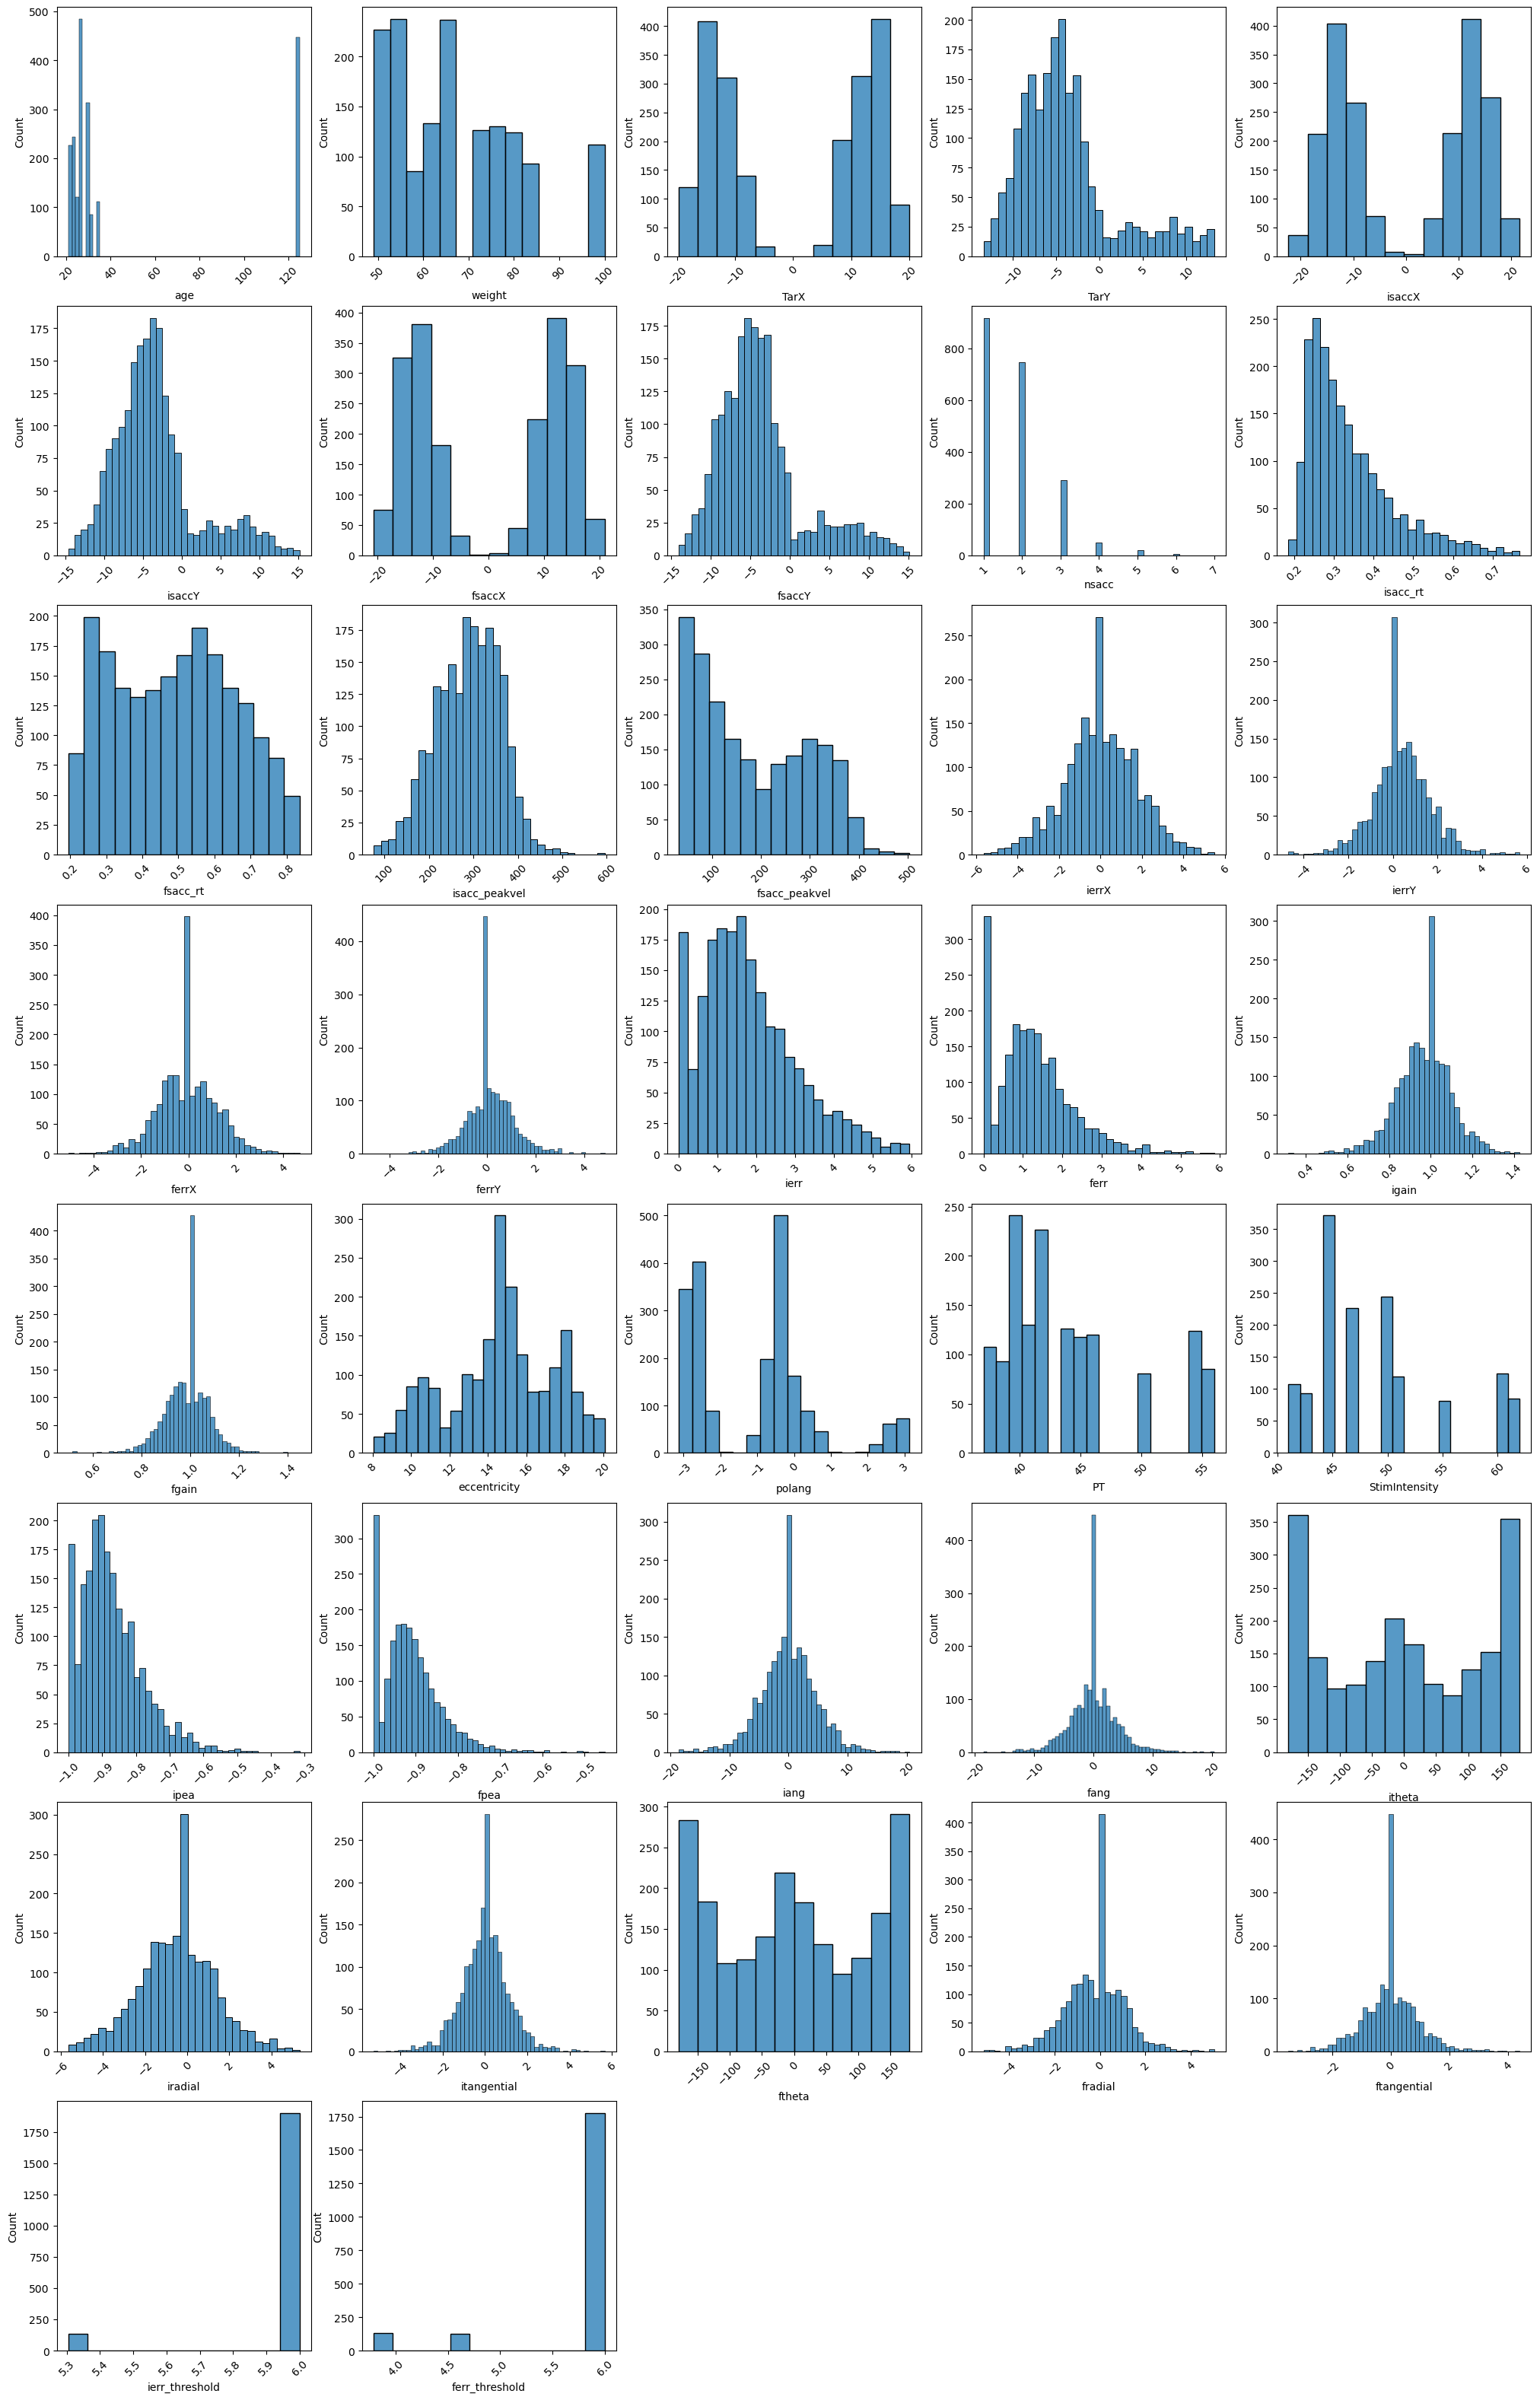

In [5]:
plt.figure(figsize=(25, 40))
for i, col in enumerate(numer_cols):
    plt.subplot(8, 5, i + 1)
    sns.histplot(x=col, data=small_df)
    plt.xticks(rotation=45)
plt.show()

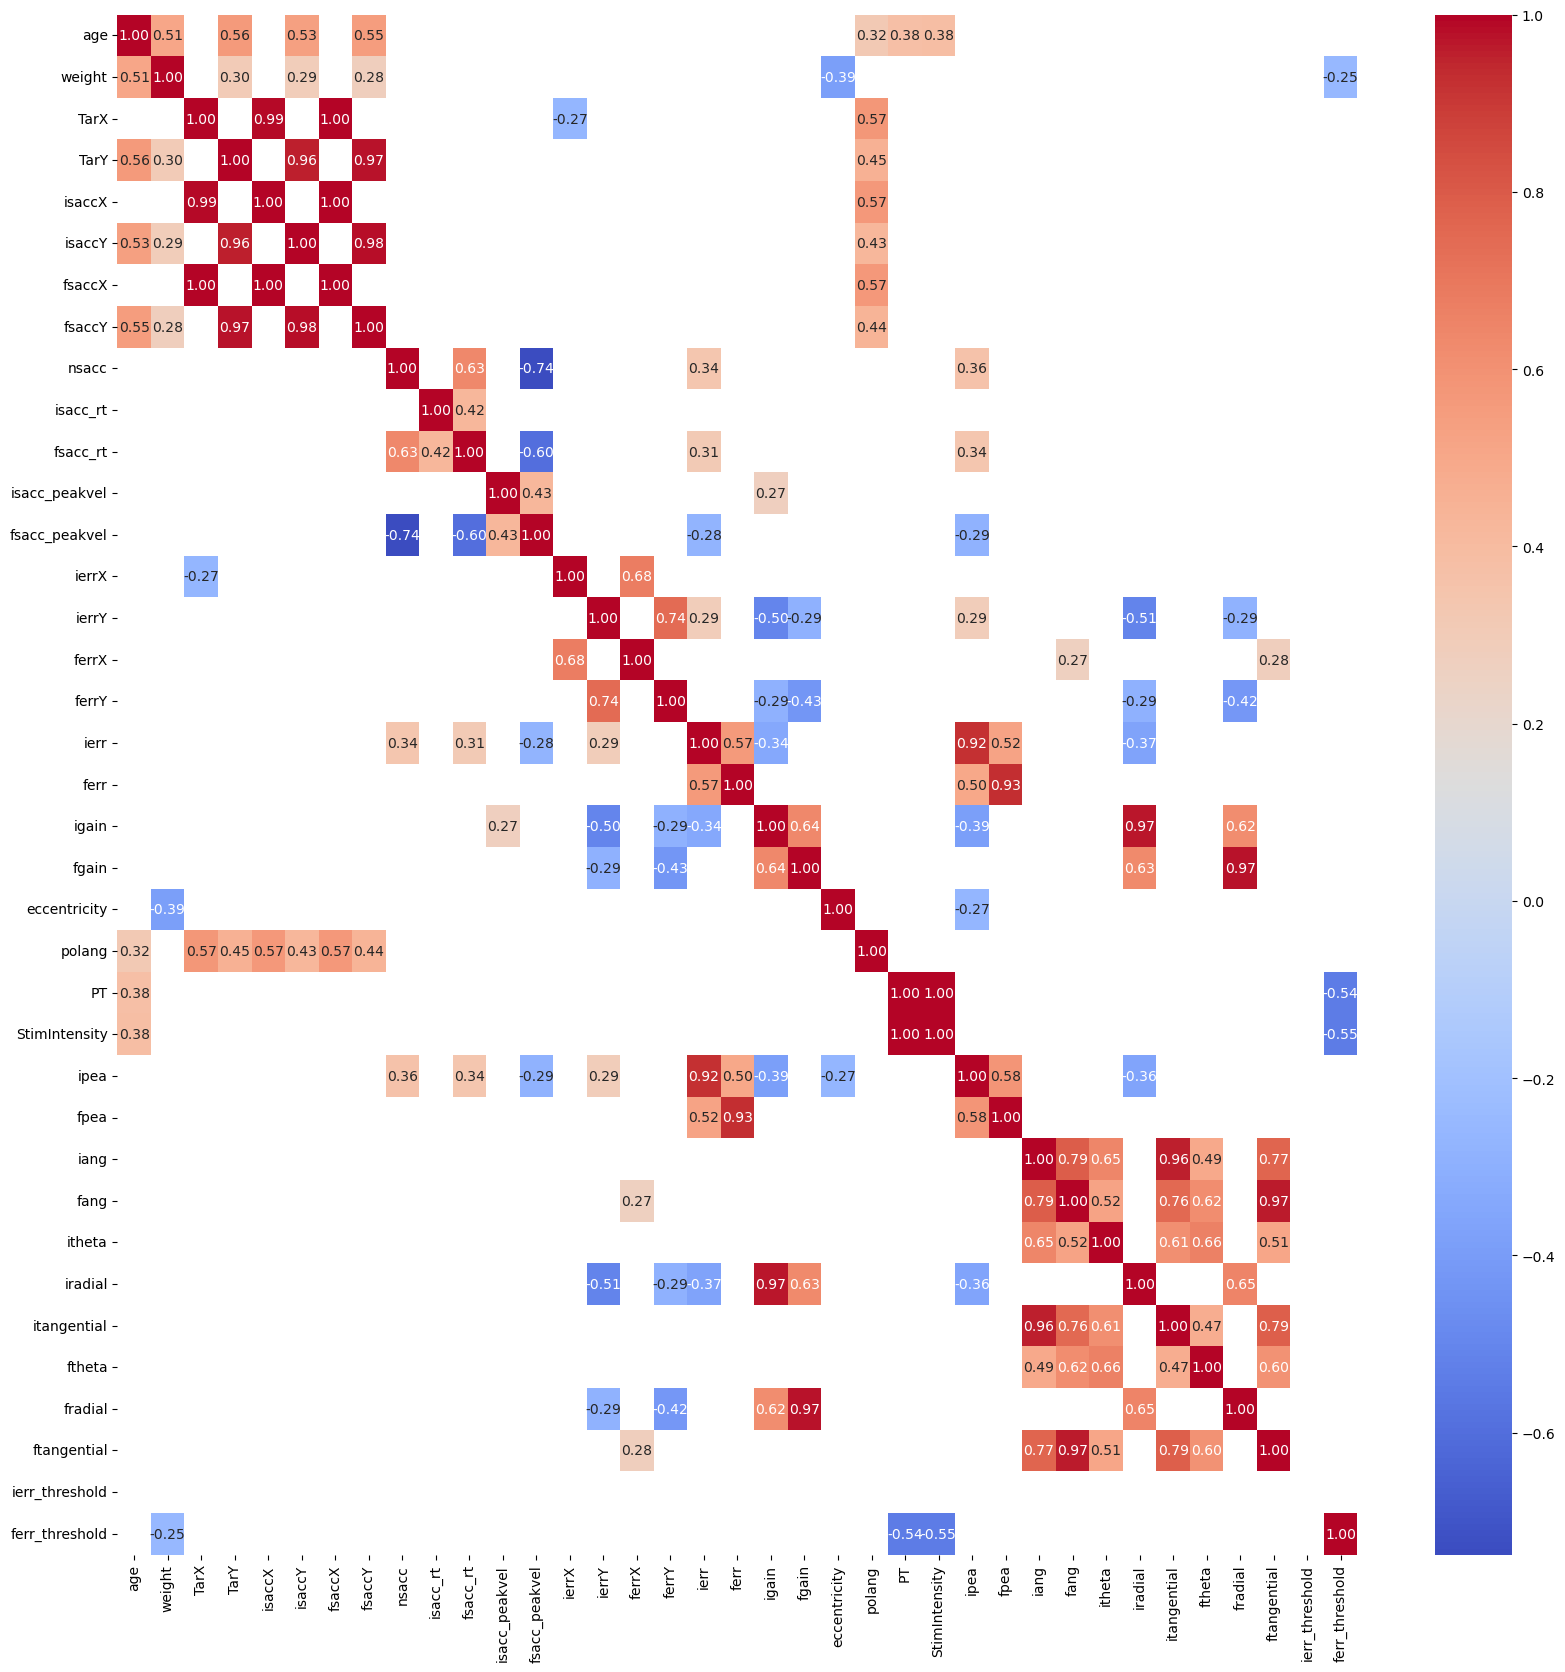

In [6]:
# Check for correlation in data
plt.figure(figsize=(20, 20))
corr_matrix = df_to_visualize[numer_cols].corr()
mask = (corr_matrix > 0.25) | (corr_matrix < -0.25)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', mask = ~mask,
            xticklabels=corr_matrix.columns, yticklabels=corr_matrix.columns)
plt.show()

### Visualize categorical columns

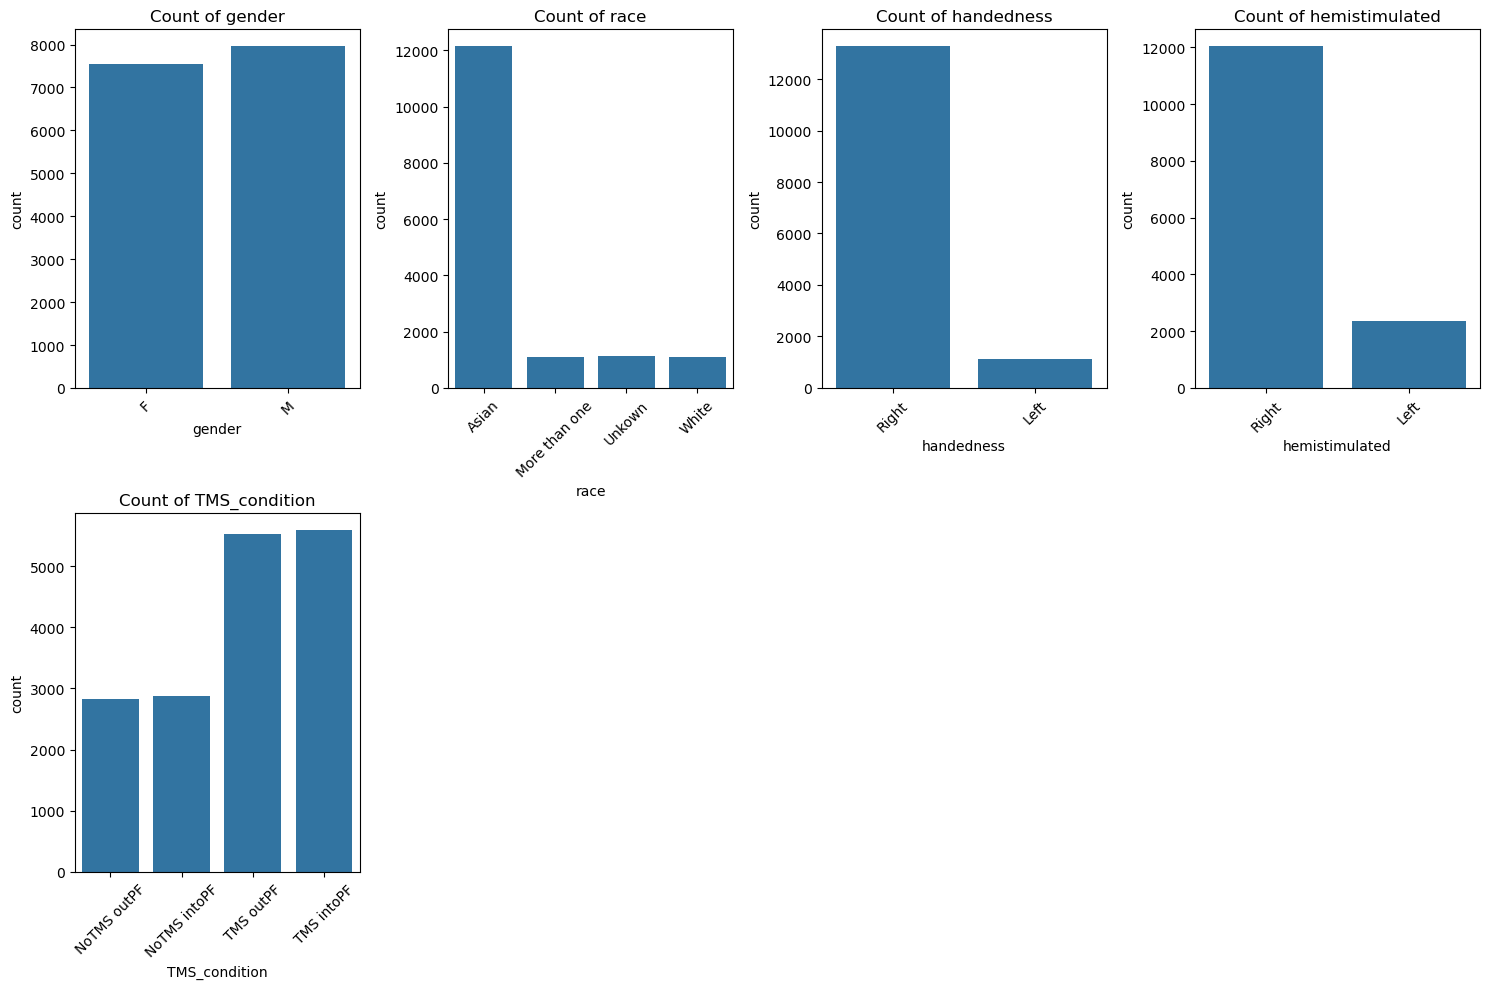

In [7]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(cat_cols):
    plt.subplot(2, 4, i + 1)
    sns.countplot(x=col, data=df_filter)
    plt.title(f'Count of {col}')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
meta_data = df_filter.groupby('subjID').agg({
    'day': 'max',
    'gender': 'first',
    'race': 'first',  
    'handedness': 'first',  
    'hemistimulated': 'first',  
    'age': 'first',
    'weight': 'first',  
    'PT': 'first',
    'StimIntensity': 'first',
    'eccentricity': 'first' 
}).reset_index()
print(meta_data.describe())

        subjID   day       age    weight       PT  StimIntensity  eccentricity
count  20.0000  20.0   20.0000   13.0000  13.0000        13.0000       20.0000
mean   11.6500   2.0   56.3000   66.8462  44.3077        49.3077       14.4943
std     6.9606   0.0   46.2523   14.7583   5.8222         6.3690        2.8278
min     1.0000   2.0   21.0000   49.0000  37.0000        41.0000        8.7386
25%     5.7500   2.0   25.7500   55.0000  40.0000        45.0000       13.4195
50%    11.5000   2.0   29.0000   64.0000  42.0000        47.0000       14.5730
75%    17.2500   2.0  125.0000   76.0000  46.0000        51.0000       16.3560
max    23.0000   2.0  125.0000  100.0000  56.0000        62.0000       19.3643


### Check #trials kept

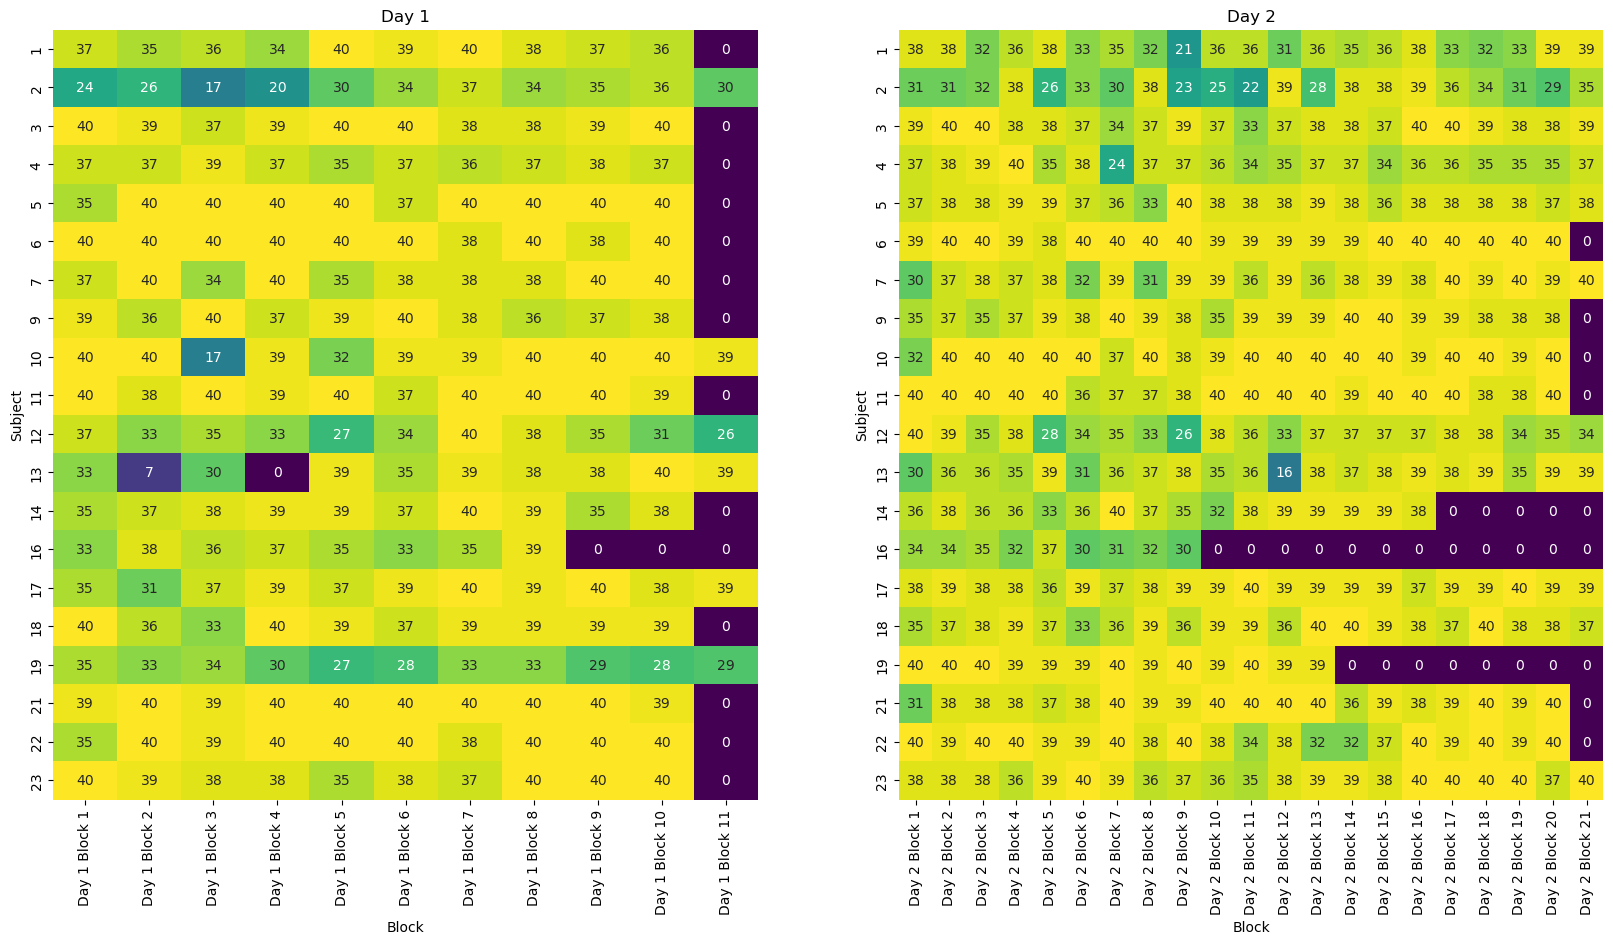

In [5]:
daywise_heatmap(df_filter, sub_list, 'trial_count')

In [6]:
## Number of trials for NoTMS and TMS for each subject
print('Expected number of trials for:')
print('For NoTMS: 200 each')
print('For TMS: 400 each')
grouped_view = df_filter.groupby(['subjID', 'instimVF', 'istms'])
grouped_view = grouped_view.size().unstack()
grouped_view

Expected number of trials for:
For NoTMS: 200 each
For TMS: 400 each


istms              0    1
subjID instimVF          
1      0         185  357
       1         186  368
2      0         147  341
       1         181  334
3      0         195  381
       1         196  415
4      0         180  360
       1         189  390
5      0         197  392
       1         195  401
6      0         198  396
       1         197  395
7      0         186  381
       1         178  388
9      0         188  380
       1         191  380
10     0         203  390
       1         211  394
11     0         194  392
       1         197  389
12     0         182  362
       1         184  371
13     0         204  388
       1         197  386
14     0         186  295
       1         191  296
16     0         144  151
       1         140  142
17     0         202  401
       1         205  401
18     0         190  397
       1         191  393
19     0         169  255
       1         168  255
21     0         200  384
       1         197  384
22     0         193  375
       1         196  381
23     0         191  405
       1         196  399

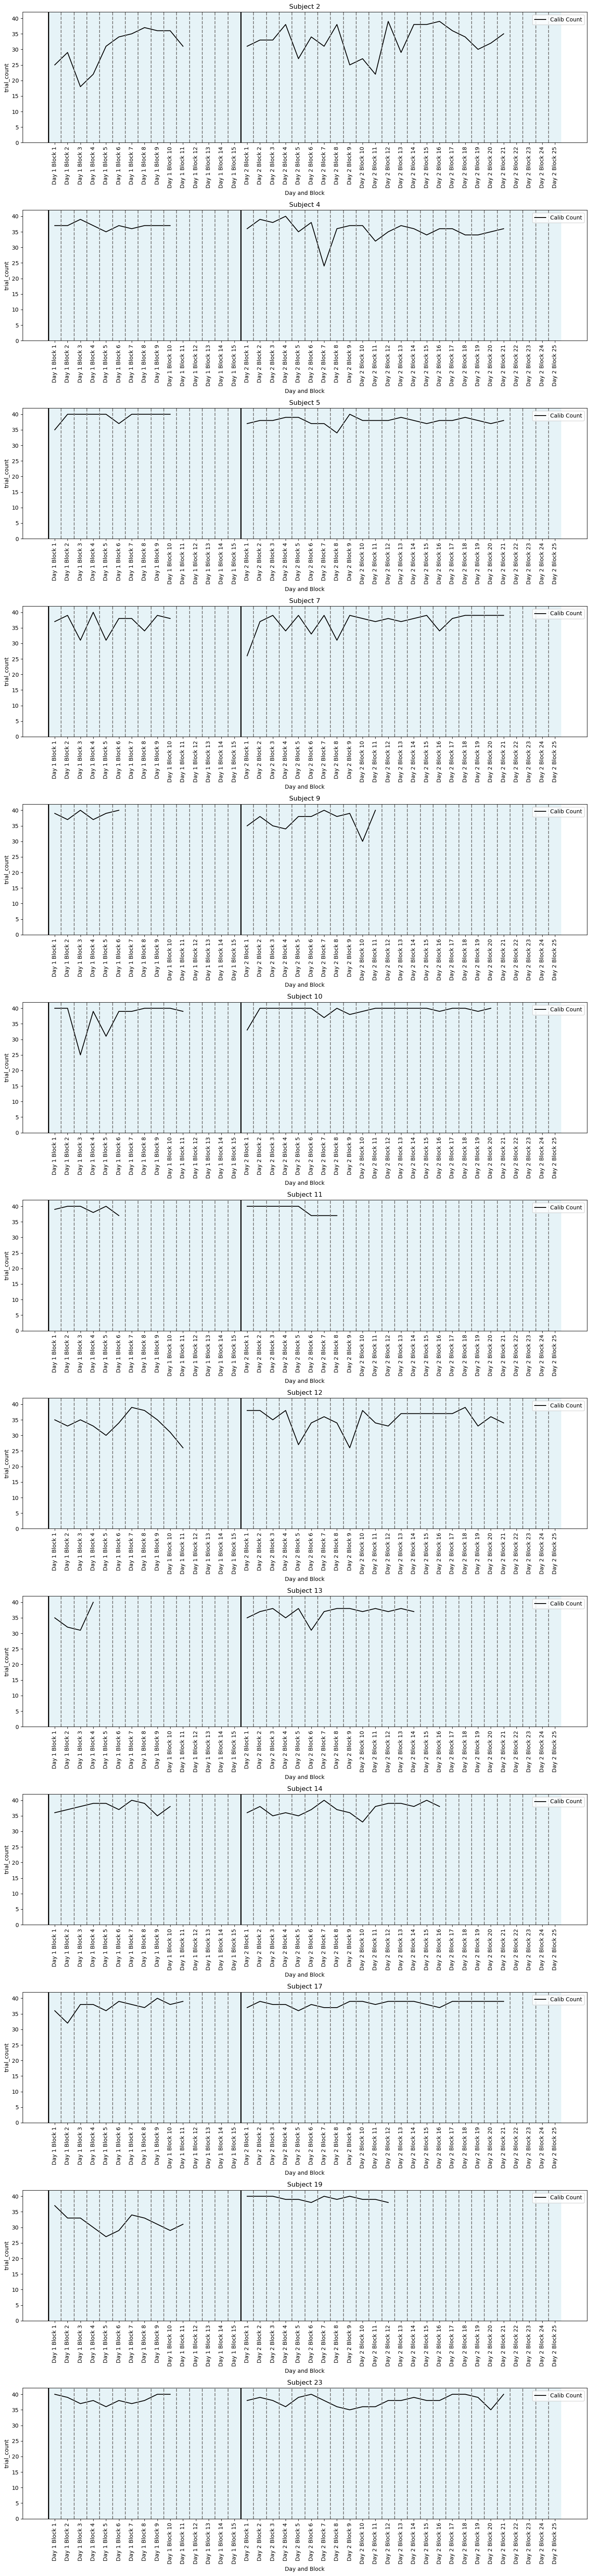

In [7]:
daywise_trend(df_filter, sub_list, 'trial_count')

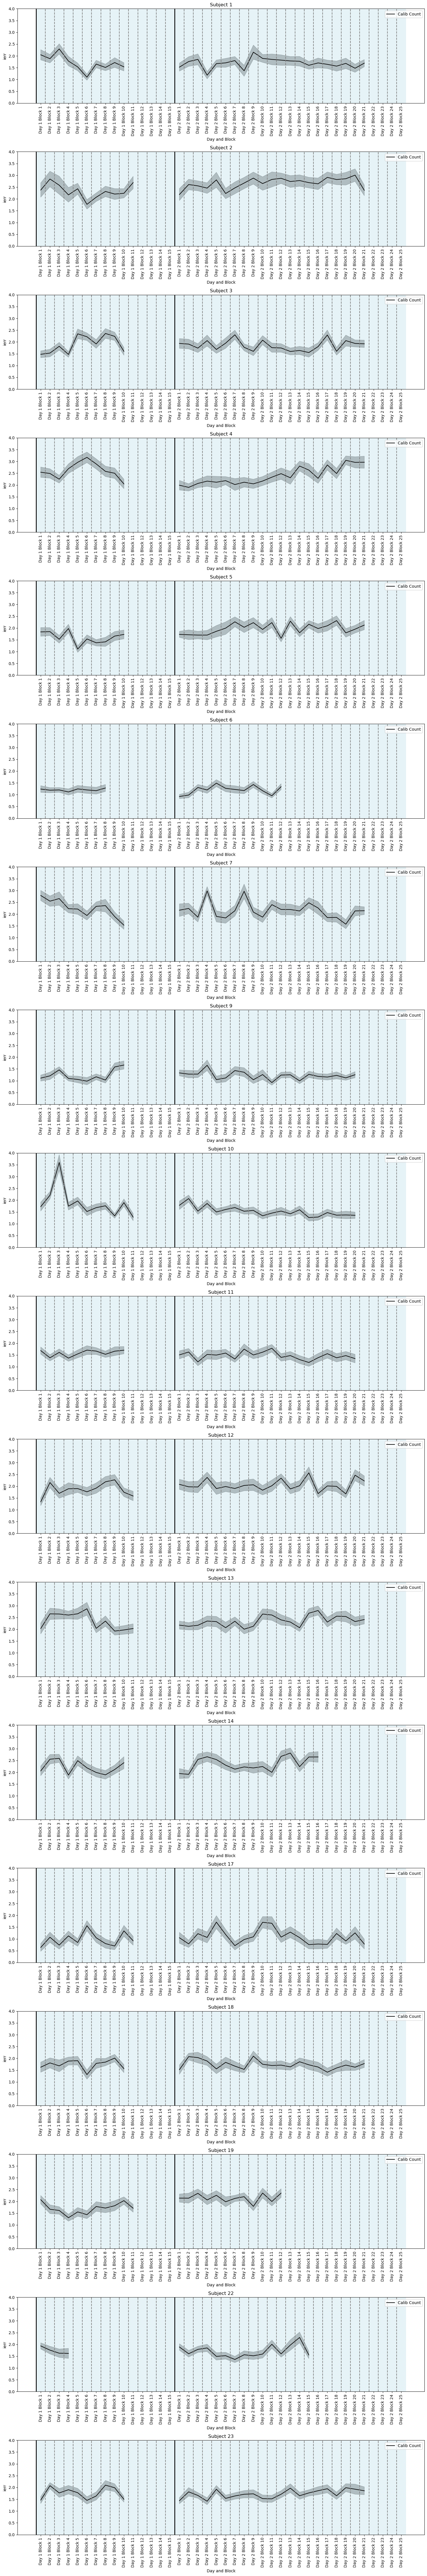

In [7]:
daywise_trend(df_filter, sub_list, 'ierr')

### Subject and block eliminations

In [6]:
subs_to_remove = []
df_clean = elim_subs_blocks(df_filter, subs_to_remove)
sub_list_clean = [ss for ss in sub_list if ss not in subs_to_remove]

Removed subjects: []
Removed blocks df1:
    subjID  day  rnum
0        1    2     9
1        2    1     1
2        2    1     3
3        2    1     4
4        2    2     9
5        2    2    10
6        2    2    11
7        4    2     7
8       10    1     3
9       13    1     2
10      13    2    12


For tms cond = notms, the number of points are: 3718
For tms cond = tms, the number of points are: 7208


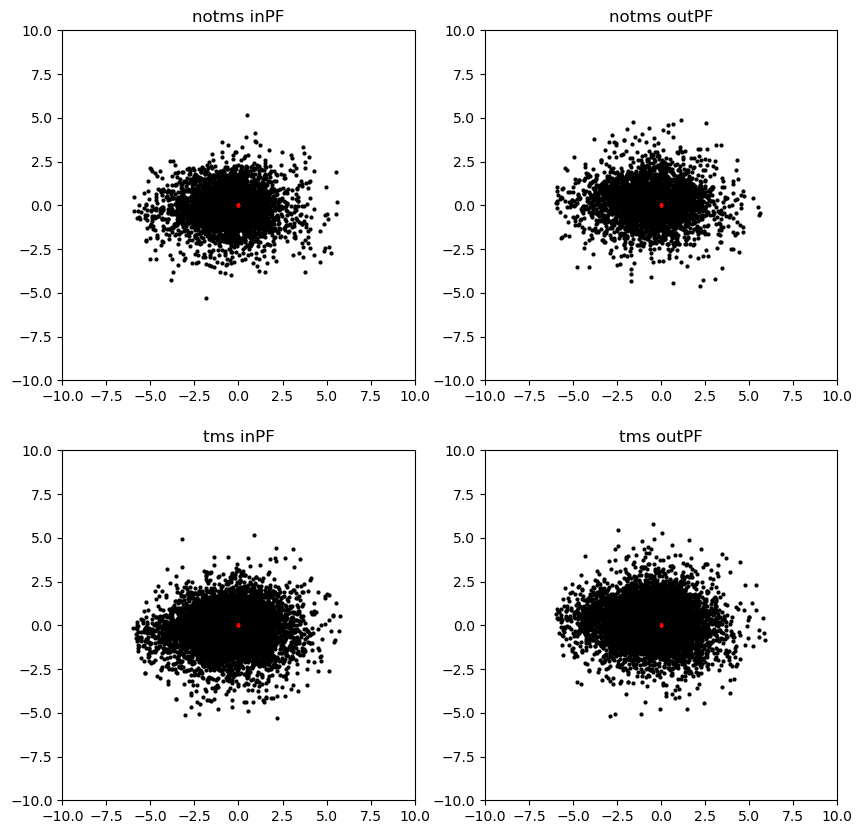

In [7]:
pwidth = 10
tms_conds = ['notms', 'tms']
f, axs = plt.subplots(2, 2, figsize=(10, 5*2))
for ii in range(len(tms_conds)):
    targXinPF, targYinPF, predXinPF, predYinPF, targXoutPF, targYoutPF, predXoutPF, predYoutPF = combine_rotated_points(tms_conds[ii], sub_list_clean, df_clean, 'initial')
    print(f"For tms cond = {tms_conds[ii]}, the number of points are: {len(predXinPF)}") 
    axs[ii, 0].plot(predXinPF, predYinPF, 'ko', markersize=2)
    axs[ii, 0].plot(targXinPF, targYinPF, 'r*', markersize=2)
    axs[ii, 0].set_xlim([-pwidth, pwidth])
    axs[ii, 0].set_ylim([-pwidth, pwidth])
    axs[ii, 0].set_title(f'{tms_conds[ii]} inPF')

    axs[ii, 1].plot(predXoutPF, predYoutPF, 'ko', markersize=2)
    axs[ii, 1].plot(targXoutPF, targYoutPF, 'r*', markersize=2)
    axs[ii, 1].set_xlim([-pwidth, pwidth])
    axs[ii, 1].set_ylim([-pwidth, pwidth])
    axs[ii, 1].set_title(f'{tms_conds[ii]} outPF')
plt.show()

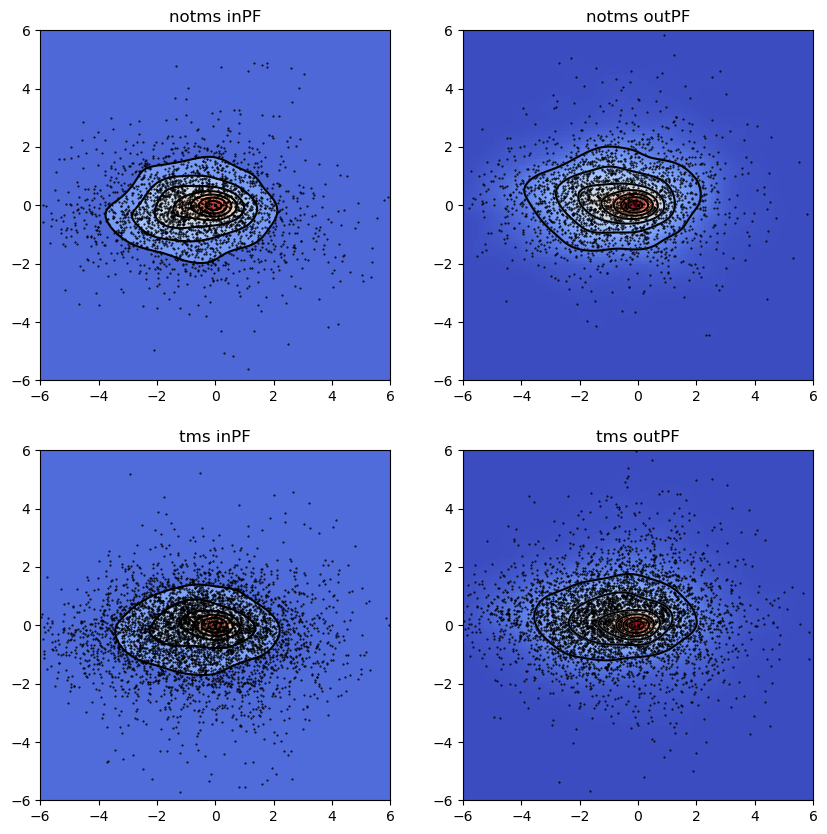

In [13]:
pwidth = 6
xx, yy = np.mgrid[-pwidth:pwidth:100j, -pwidth:pwidth:100j]
positions = np.vstack([xx.ravel(), yy.ravel()])

tms_conds = ['notms', 'tms']
f, axs = plt.subplots(2, 2, figsize=(10, 5*2))
for ii in range(len(tms_conds)):
    targXinPF, targYinPF, predXinPF, predYinPF, targXoutPF, targYoutPF, predXoutPF, predYoutPF = combine_rotated_points(tms_conds[ii], sub_list_clean, df_clean, 'initial')
    axs[ii, 0].plot(predXinPF, predYinPF, 'ko', markersize=0.5)
    # axs[ii, 0].plot(targXinPF, targYinPF, 'r*', markersize=2)
    predIN = np.vstack([predXinPF, predYinPF])
    kernelIN = stats.gaussian_kde(predIN)
    fIN = np.reshape(kernelIN(positions).T, xx.shape)
    cfset = axs[ii, 0].contourf(xx, yy, fIN, cmap = 'coolwarm')
    axs[ii, 0].imshow(np.rot90(fIN), cmap = 'coolwarm', extent=[-pwidth, pwidth, -pwidth, pwidth])
    cset = axs[ii, 0].contour(xx, yy, fIN, colors = 'k')
    axs[ii, 0].set_xlim([-pwidth, pwidth])
    axs[ii, 0].set_ylim([-pwidth, pwidth])
    axs[ii, 0].set_title(f'{tms_conds[ii]} inPF')

    axs[ii, 1].plot(predXoutPF, predYoutPF, 'ko', markersize=0.5)
    # axs[ii, 1].plot(targXoutPF, targYoutPF, 'r*', markersize=2)
    predOUT = np.vstack([predXoutPF, predYoutPF])
    kernelOUT = stats.gaussian_kde(predOUT)
    fOUT = np.reshape(kernelOUT(positions).T, xx.shape)
    cfset = axs[ii, 1].contour(xx, yy, fOUT, cmap = 'coolwarm')
    axs[ii, 1].imshow(np.rot90(fOUT), cmap = 'coolwarm', extent=[-pwidth, pwidth, -pwidth, pwidth])
    cset = axs[ii, 1].contour(xx, yy, fOUT, colors = 'k')
    # sns.kdeplot(x=predXoutPF, y=predYoutPF, ax = axs[ii, 1],  cmap="Purples_r", fill=True)
    axs[ii, 1].set_xlim([-pwidth, pwidth])
    axs[ii, 1].set_ylim([-pwidth, pwidth])
    axs[ii, 1].set_title(f'{tms_conds[ii]} outPF')
# plt.savefig('/d/DATA/hyper/manuscripts/Dake_Curtis_2024/saccdist_initial.eps', format = 'eps', dpi = 1200)
plt.show()

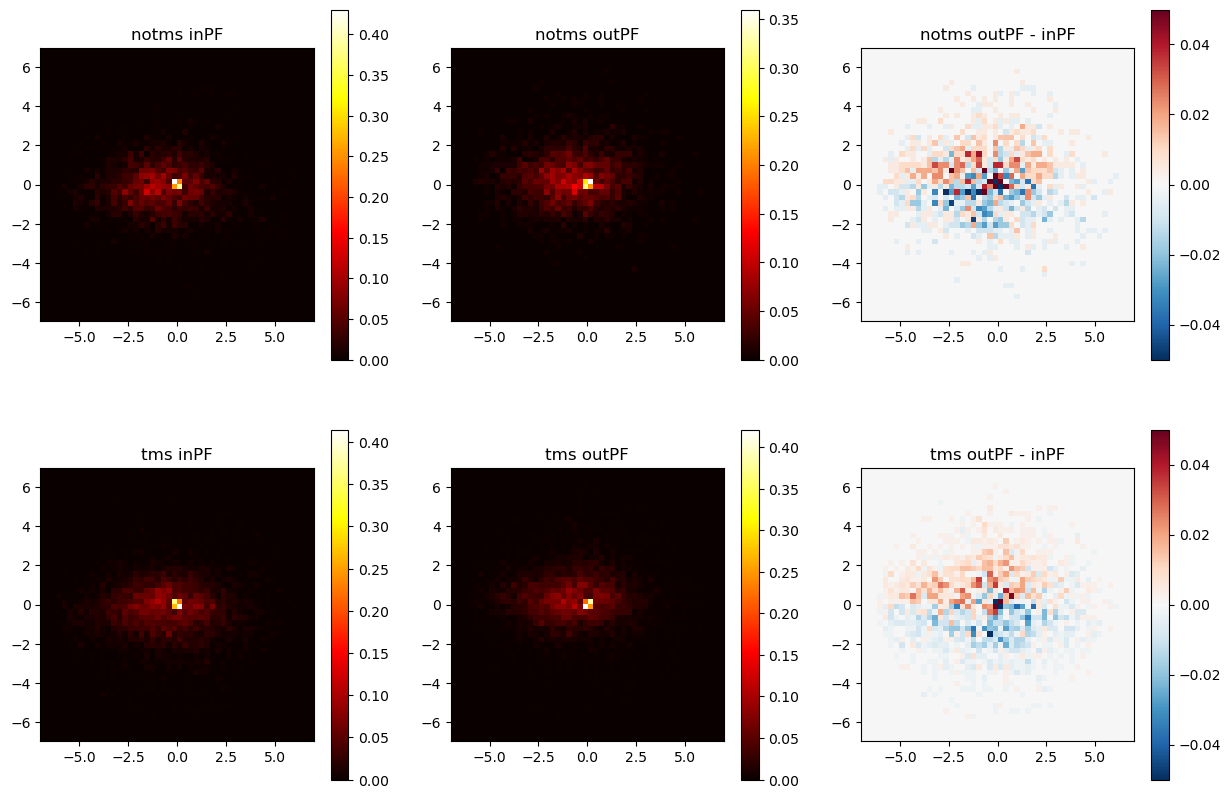

In [14]:
pwidth = 7
tms_conds = ['notms', 'tms']
f, axs = plt.subplots(2, 3, figsize=(15, 5*2))
for ii in range(len(tms_conds)):
    targXinPF, targYinPF, predXinPF, predYinPF, targXoutPF, targYoutPF, predXoutPF, predYoutPF = combine_rotated_points(tms_conds[ii], sub_list_clean, df_clean, 'initial')
    heatmapin, xedgesin, yedgesin = np.histogram2d(predXinPF, predYinPF, bins=50, density=True, range=[[-pwidth, pwidth], [-pwidth, pwidth]])

    im0 = axs[ii, 0].imshow(heatmapin.T, extent=[xedgesin[0], xedgesin[-1], yedgesin[0], yedgesin[-1]], origin='lower', cmap='hot')
    axs[ii, 0].set_xlim([-pwidth, pwidth])
    axs[ii, 0].set_ylim([-pwidth, pwidth])
    axs[ii, 0].set_title(f'{tms_conds[ii]} inPF')
    f.colorbar(im0, ax=axs[ii, 0], orientation='vertical')

    heatmapout, xedgesout, yedgesout = np.histogram2d(predXoutPF, predYoutPF, bins=50, density=True, range=[[-pwidth, pwidth], [-pwidth, pwidth]])
    im1 = axs[ii, 1].imshow(heatmapout.T, extent=[xedgesout[0], xedgesout[-1], yedgesout[0], yedgesout[-1]], origin='lower', cmap='hot')
    axs[ii, 1].set_xlim([-pwidth, pwidth])
    axs[ii, 1].set_ylim([-pwidth, pwidth])
    axs[ii, 1].set_title(f'{tms_conds[ii]} outPF')
    f.colorbar(im1, ax=axs[ii, 1], orientation='vertical')

    im2 = axs[ii, 2].imshow((heatmapout-heatmapin).T, extent=[xedgesout[0], xedgesout[-1], yedgesout[0], yedgesout[-1]], origin='lower', cmap='RdBu_r', vmin = -0.05, vmax=0.05)
    axs[ii, 2].set_xlim([-pwidth, pwidth])
    axs[ii, 2].set_ylim([-pwidth, pwidth])
    axs[ii, 2].set_title(f'{tms_conds[ii]} outPF - inPF')
    f.colorbar(im2, ax=axs[ii, 2], orientation='vertical')
# plt.savefig('/d/DATA/hyper/manuscripts/Dake_Curtis_2024/saccdist_initial_heatmap.eps', format = 'eps', dpi = 1200)
plt.show()

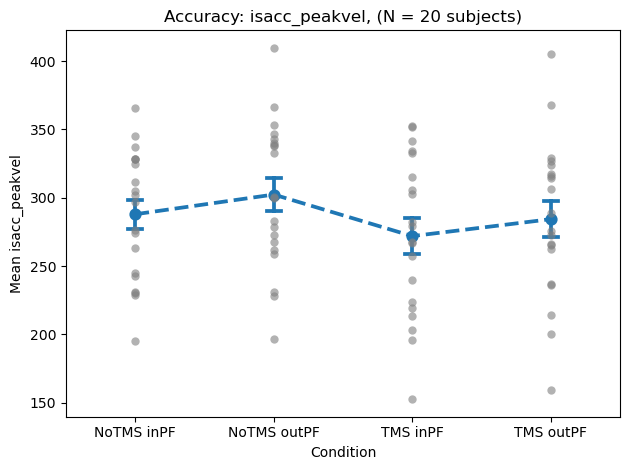

Mean and SE for each condition
                 mean       se
Condition                     
NoTMS inPF   287.9707  41.0874
NoTMS outPF  302.3767  42.0696
TMS inPF     271.9775  42.3849
TMS outPF    284.3616  45.2556
ANOVA for the metric


,Source,ddof1,ddof2,F,p-unc,p-GG-corr,ng2,eps,sphericity,W-spher,p-spher
0,Condition,3,57,8.6925,7.6975e-05,0.002,0.04,0.5304,False,0.1227,5.8471e-07


In [14]:
metric = 'isacc_peakvel'
conds_all5 = {
    'NoTMS inPF': df_clean[(df_clean['TMS_condition'] == 'NoTMS intoPF')],
    'NoTMS outPF': df_clean[(df_clean['TMS_condition'] == 'NoTMS outPF')],

    # 'NoTMS': df_clean[(df_clean['TMS_condition'] == 'NoTMS intoPF') | (df_clean['TMS_condition'] == 'NoTMS outPF')],
    # 'No TMS inPF': df_clean[(df_clean['TMS_condition'] == 'No TMS')  & (df_clean['instimVF'] == 1)],
    # 'No TMS outPF': df_clean[(df_clean['TMS_condition'] == 'No TMS')  & (df_clean['instimVF'] == 0)],
    'TMS inPF': df_clean[(df_clean['TMS_condition'] == 'TMS intoPF')],
    'TMS outPF': df_clean[(df_clean['TMS_condition'] == 'TMS outPF')],
}

if metric == 'ierr':
    y_range = [0, 3]
elif metric == 'ferr':
    y_range = [0, 2]
elif metric == 'isacc_rt':
    y_range = [0, 0.6]

results_all5 = {cond: data.groupby('subjID').apply(calculate_mean_and_se, error_metric=metric) for cond, data in conds_all5.items()}
combined_all5 = pd.concat(results_all5, names=['Condition']).reset_index()
combined_all5['PF'] = combined_all5['Condition'].apply(lambda x: 1 if 'inPF' in x else 0)

plt.figure()
sns.stripplot(data=combined_all5, x='Condition', y='mean', color="grey", alpha = 0.6, jitter=False, size=6)
sns.pointplot(data=combined_all5, x='Condition', y='mean', linestyle="--", capsize=.1, errorbar="se")
plt.title(f'Accuracy: {metric}, (N = {len(sub_list_clean)} subjects)')
plt.ylabel(f'Mean {metric}')
plt.xlabel('Condition')
plt.tight_layout()
plt.show()

print('Mean and SE for each condition')
print(combined_all5.groupby('Condition').agg({'mean': 'mean', 'se': 'mean'}))
print('ANOVA for the metric')
pg.rm_anova(data=combined_all5, dv='mean', within='Condition', subject='subjID')

## Pairwise Plots

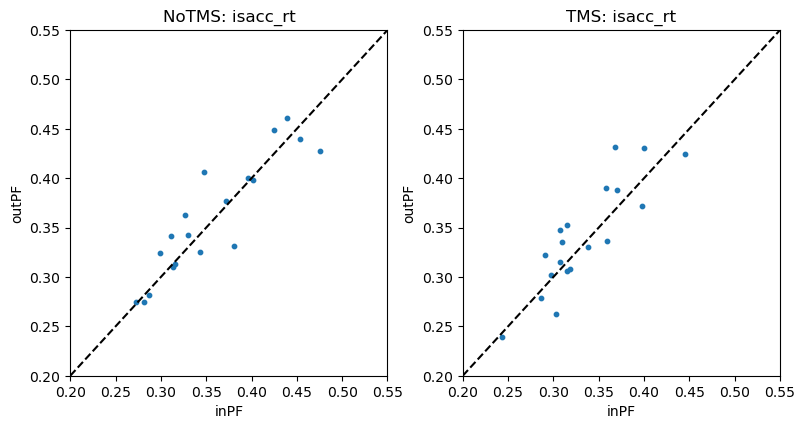

In [20]:
plt.figure(figsize=(8, 8))
conds_to_plot = ['NoTMS', 'TMS']
metric_to_plot = 'isacc_rt'
if metric_to_plot == 'ierr':
    mlim_val = 0
    lim_val = 3
elif metric_to_plot == 'ferr':
    mlim_val = 0
    lim_val = 2
elif metric_to_plot == 'isacc_rt':
    mlim_val = 0.2
    lim_val = 0.55
elif metric_to_plot == 'fsacc_rt':
    mlim_val = 0.2
    lim_val = 0.55
elif metric_to_plot == 'isacc_peakvel':
    mlim_val = 100
    lim_val = 500
# lim_val = 2
for i, ccnd in enumerate(conds_to_plot, 1):
    plt.subplot(2, 2, i)

    df_inVF = df_clean[(df_clean['istms'] == i-1) & (df_clean['instimVF'] == 1)]
    df_outVF = df_clean[(df_clean['istms'] == i-1) & (df_clean['instimVF'] == 0)]

    # Create summary of error for each subject for each condition
    df_inVF_summary = df_inVF.groupby(['subjID']).agg({
        'ierr': ['mean', 'sem'],
        'ferr': ['mean', 'sem'],
        'isacc_rt': ['mean', 'sem'],
        'fsacc_rt': ['mean', 'sem'],
        'isacc_peakvel': ['mean', 'sem'],
        'fsacc_peakvel': ['mean', 'sem'],
        'nsacc': ['mean', 'sem'],
        'ipea': ['mean', 'sem'],
    }).reset_index()

    df_outVF_summary = df_outVF.groupby(['subjID']).agg({
        'ierr': ['mean', 'sem'],
        'ferr': ['mean', 'sem'],
        'isacc_rt': ['mean', 'sem'],
        'fsacc_rt': ['mean', 'sem'],
        'isacc_peakvel': ['mean', 'sem'],
        'fsacc_peakvel': ['mean', 'sem'],
        'nsacc': ['mean', 'sem'],
        'ipea': ['mean', 'sem'],
    }).reset_index()

    # Select column with error metric and only mean
    df_inVF_selected = df_inVF_summary[(metric_to_plot, 'mean')].values
    df_outVF_selected = df_outVF_summary[(metric_to_plot, 'mean')].values

    # Create a scatter plot
    plt.scatter(df_inVF_selected, df_outVF_selected, s=msize)
    plt.plot([mlim_val, lim_val], [mlim_val, lim_val], 'k--')
    plt.xlim([mlim_val, lim_val])
    plt.ylim([mlim_val, lim_val])
    plt.title(f'{ccnd}')
    plt.xlabel(f'inPF')
    plt.ylabel(f'outPF')
    plt.title(f'{ccnd}: {metric_to_plot}')
                               
plt.tight_layout()
plt.show()

In [17]:
merged_df

ierr        
      mean    mean
0   1.7646  1.6295
1   2.1414  2.4642
2   2.2948  2.9329
3   1.4640  1.7301
4   2.1759  2.2947
5   1.2001  1.2677
6   2.0594  1.5833
7   1.5483  1.6236
8   1.7030  2.0348
9   2.5620  2.1125
10  2.4189  2.0072
11  0.8510  1.1151
12  1.6927  1.7396
13  1.8639  1.5517
14  1.6638  1.8704

## Statistics

In [ ]:
def get_summary(df_all5, metric):
    conds_all5_analysis = {
        'No TMS inVF': df_all5[(df_all5['istms'] == 0) & (df_all5['instimVF'] == 1) & (df_all5['day'].isin([1, 2, 3]))],
        'No TMS outVF': df_all5[(df_all5['istms'] == 0) & (df_all5['instimVF'] == 0) & (df_all5['day'].isin([1, 2, 3]))],
        'mid inVF': df_all5[(df_all5['istms'] == 1) & (df_all5['instimVF'] == 1) & (df_all5['day'].isin([1, 2, 3]))],
        'mid outVF': df_all5[(df_all5['istms'] == 1) & (df_all5['instimVF'] == 0) & (df_all5['day'].isin([1, 2, 3]))],
        'early inVF': df_all5[(df_all5['istms'] == 1) & (df_all5['instimVF'] == 1) & (df_all5['day'] == 4)],
        'early outVF': df_all5[(df_all5['istms'] == 1) & (df_all5['instimVF'] == 0) & (df_all5['day'] == 4)],
        'mid dangit inVF': df_all5[(df_all5['istms'] == 1) & (df_all5['instimVF'] == 1) & (df_all5['day'] == 5)],
        'mid dangit outVF': df_all5[(df_all5['istms'] == 1) & (df_all5['instimVF'] == 0) & (df_all5['day'] == 5)],
    }
    
    results_all5_analysis = {cond: data.groupby('subjID').apply(calculate_mean_and_se, error_metric=metric) for cond, data in conds_all5_analysis.items()}
    combined_all5_analysis = pd.concat(results_all5_analysis, names=['Condition']).reset_index()
    combined_all5_analysis['time'] = combined_all5_analysis['Condition'].apply(lambda x: 'notms' if 'No TMS' in x else ('early' if 'early' in x else ('mid dangit' if 'mid dangit' in x else 'mid')))
    combined_all5_analysis['VF'] = combined_all5_analysis['Condition'].apply(lambda x: 1 if 'inVF' in x else 0)
    return combined_all5_analysis

def compute_stats_parametric(df, pairs_to_test):
    tvect = np.zeros((len(pairs_to_test),))
    for i, (time1, VF1, time2, VF2, _) in enumerate(pairs_to_test):
        data1 = df[(df['time'] == time1) & (df['VF'] == VF1)]['mean']
        data2 = df[(df['time'] == time2) & (df['VF'] == VF2)]['mean']
        tstat, _ = stats.ttest_rel(data1, data2, nan_policy = 'omit', alternative='two-sided')
        tvect[i] = tstat
    return tvect
    

start = time.time()
iter_count = 1000
pairs_to_test = [
    ('early', 1, 'early', 0, 'early in vs out'),
    ('mid', 1, 'mid', 0, 'mid in vs out'),
    ('mid dangit', 1, 'mid dangit', 0, 'mid dangit in vs out'),
    ('early', 1, 'notms', 1, 'notms vs early for inVF'),
    ('early', 0, 'notms', 0, 'notms vs early for outVF'),
    ('mid', 1, 'notms', 1, 'notms vs mid for inVF'),
    ('mid', 1, 'mid dangit', 1, 'mid vs mid dangit for inVF')
]
n_tests = len(pairs_to_test)
n_cols = 2 
n_rows = n_tests // n_cols + (n_tests % n_cols > 0)

tstat_compiled = np.zeros((iter_count, len(pairs_to_test)))
    
for ii in range(iter_count):
    #df_temp = df_calib_all5_filt.copy()
    df_temp = df_calib_all5_filt[df_calib_all5_filt['ispro']==1]
    istms_shuffle = np.random.permutation(df_temp['istms'])
    stimVF_shuffle = np.random.permutation(df_temp['instimVF'])
    day_shuffle = np.random.permutation(df_temp['day'])
    df_temp['istms'] = istms_shuffle
    df_temp['instimVF'] = stimVF_shuffle
    df_temp['day'] = day_shuffle
    df_analysis = get_summary(df_temp, 'ferr')
    tvect_this = compute_stats_parametric(df_analysis, pairs_to_test)
    tstat_compiled[ii, :] = tvect_this

df_analysis_real = get_summary(df_calib_all5_filt, 'ferr')
tstat_real = compute_stats_parametric(df_analysis_real, pairs_to_test)
pval_2side = []
pval_1side = []
for ii in range(n_tests):
    if tstat_real[ii] >= 0:
        samps_bothside = sum(tstat_compiled[:, ii] >= tstat_real[ii]) + sum(tstat_compiled[:, ii] < -tstat_real[ii])
    else:
        samps_bothside = sum(tstat_compiled[:, ii] >= -tstat_real[ii]) + sum(tstat_compiled[:, ii] < tstat_real[ii])
    samps_oneside = sum(tstat_compiled[:, ii] >= tstat_real[ii])
    pval_2side.append(samps_bothside/iter_count)
    pval_1side.append(samps_oneside/iter_count)
print(f"Total time taken for running {iter_count} permutations: {round(time.time()-start, 3)} s")

## Repeated-measures ANOVA

In [12]:
df_calib_all5_filt.columns

Index(['subjID', 'day', 'gender', 'race', 'handedness', 'hemistimulated',
       'age', 'weight', 'eegsize', 'PT', 'StimIntensity', 'rnum', 'tnum',
       'istms', 'ispro', 'instimVF', 'TarX', 'TarY', 'isaccX', 'isaccY',
       'fsaccX', 'fsaccY', 'nsacc', 'isacc_rt', 'fsacc_rt', 'isacc_peakvel',
       'fsacc_peakvel', 'itidur', 'trialdur', 'trial_type', 'TMS_condition',
       'ierrX', 'ierrY', 'ferrX', 'ferrY', 'ierr', 'ferr', 'igain', 'fgain',
       'eccentricity', 'polang', 'ipea', 'fpea', 'iang', 'fang', 'itheta',
       'iradial', 'itangential', 'ftheta', 'fradial', 'ftangential',
       'TMS_time', 'ierr_threshold', 'ferr_threshold'],
      dtype='object')

In [14]:
pg.rm_anova(data=df_calib_all5_filt, dv='ierr', within=['TMS_time', 'instimVF'], detailed=True, subject='subjID')


/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,TMS_time,0.2521,3,42,0.0840,1.5065,0.2268,0.2406,0.0107,0.6108
1,instimVF,1.2363,1,14,1.2363,9.6342,0.0078,0.0078,0.0503,1.0000
2,TMS_time * instimVF,0.2351,3,42,0.0784,3.4358,0.0253,0.0358,0.0100,0.8073


In [ ]:
pairs_to_test = [
    ('notms inVF', 'early inVF', 'notms vs early inVF'),
    ('notms inVF', 'mid inVF', 'notms vs mid inVF'),
    ('notms outVF', 'early outVF', 'notms vs early outVF'),
    ('notms outVF', 'mid outVF', 'notms vs mid outVF'),
    ('mid inVF', 'mid outVF', 'mid in vs out'),
    ('early inVF', 'early outVF', 'early in vs out'),
    ('mid inVF', 'mid dangit inVF', 'mid vs mid dangit inVF'),
]
n_tests = len(pairs_to_test)
n_cols = 2 
n_rows = n_tests // n_cols + (n_tests % n_cols > 0)
iter_count = 10000

metric = 'ierr'
pro_vs_anti = 'pro'
df_type = 'all5'
tstat_real, tstat_permuted, pval_1side, pval_2side = perform_permutation_test(df_calib_all5_filt, pro_vs_anti,
                                                                              pairs_to_test, metric, iter_count,
                                                                              df_type)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 5))
if n_rows > 1:
    axes = axes.flatten()
else:
    axes = [axes]
for i in range(len(pairs_to_test)):
    plot_permutation_result(tstat_permuted, tstat_real, pval_2side, pval_1side, i, pairs_to_test, axes[i])
plt.show()

In [ ]:
pairs_to_test = [
    ('notms inVF', 'notms outVF', 'notms inVF vs outVF'),
    ('notms inVF', 'TMS inVF', 'notms inVF vs TMS inVF'),
    ('notms outVF', 'TMS outVF', 'notms outVF vs TMS outVF'),
    ('TMS inVF', 'TMS outVF', 'TMS in vs out'),
]
n_tests = len(pairs_to_test)
n_cols = 2 
n_rows = n_tests // n_cols + (n_tests % n_cols > 0)
iter_count = 10000

metric = 'ierr'
pro_vs_anti = 'pro'
df_type = 'first_three'
df_input = df_calib_filt[df_calib_filt['day']<4]
tstat_real, tstat_permuted, pval_1side, pval_2side = perform_permutation_test(df_input, pro_vs_anti,
                                                                              pairs_to_test, metric, iter_count,
                                                                              df_type)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 5))
if n_rows > 1:
    axes = axes.flatten()
else:
    axes = [axes]
for i in range(len(pairs_to_test)):
    plot_permutation_result(tstat_permuted, tstat_real, pval_2side, pval_1side, i, pairs_to_test, axes[i])
plt.suptitle(pro_vs_anti+': '+df_type)
plt.show()

In [ ]:
pairs_to_test = [
    ('notms inVF', 'notms outVF', 'notms inVF vs outVF'),
    ('notms inVF', 'TMS inVF', 'notms inVF vs TMS inVF'),
    ('notms outVF', 'TMS outVF', 'notms outVF vs TMS outVF'),
    ('TMS inVF', 'TMS outVF', 'TMS in vs out'),
]
n_tests = len(pairs_to_test)
n_cols = 2 
n_rows = n_tests // n_cols + (n_tests % n_cols > 0)
iter_count = 10000

metric = 'ierr'
pro_vs_anti = 'anti'
df_type = 'first_three'
df_input = df_calib_filt[df_calib_filt['day']<4]
tstat_real, tstat_permuted, pval_1side, pval_2side = perform_permutation_test(df_input, pro_vs_anti,
                                                                              pairs_to_test, metric, iter_count,
                                                                              df_type)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 5))
if n_rows > 1:
    axes = axes.flatten()
else:
    axes = [axes]
for i in range(len(pairs_to_test)):
    plot_permutation_result(tstat_permuted, tstat_real, pval_2side, pval_1side, i, pairs_to_test, axes[i])
plt.suptitle(pro_vs_anti+': '+df_type)
plt.show()

In [ ]:
pairs_to_test = [
   # ('notms inVF', 'notms outVF', 'notms inVF vs outVF'),
    ('notms', 'mid inVF', 'notms vs mid inVF'),
    # ('notms', 'mid outVF', 'notms vs mid outVF'),
    ('mid inVF', 'mid outVF', 'mid in vs out'),
    ('notms', 'early inVF', 'notms vs early inVF'),
    # ('notms', 'early outVF', 'notms vs early outVF'),
    ('early inVF', 'early outVF', 'early in vs out'),
]
n_tests = len(pairs_to_test)
n_cols = 2 
n_rows = n_tests // n_cols + (n_tests % n_cols > 0)
iter_count = 10000

metric = 'ierr'
pro_vs_anti = 'pro'
df_type = 'clubbed'
df_input = df_calib_all5_filt#[df_calib_filt['day']<5]
tstat_real, tstat_permuted, pval_1side, pval_2side = perform_permutation_test(df_input, pro_vs_anti,
                                                                              pairs_to_test, metric, iter_count,
                                                                              df_type)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 5))
if n_rows > 1:
    axes = axes.flatten()
else:
    axes = [axes]
for i in range(len(pairs_to_test)):
    plot_permutation_result(tstat_permuted, tstat_real, pval_2side, pval_1side, i, pairs_to_test, axes[i])
plt.suptitle(pro_vs_anti+': '+df_type)
plt.show()

In [ ]:
pairs_to_test = [
   # ('notms inVF', 'notms outVF', 'notms inVF vs outVF'),
    ('notms', 'TMS inVF', 'notms vs TMS inVF'),
    ('notms', 'TMS outVF', 'notms vs TMS outVF'),
    ('TMS inVF', 'TMS outVF', 'TMS in vs out'),
]
n_tests = len(pairs_to_test)
n_cols = 2 
n_rows = n_tests // n_cols + (n_tests % n_cols > 0)
iter_count = 10000

metric = 'ierr'
pro_vs_anti = 'anti'
df_type = 'clubbed'
df_input = df_calib_filt[df_calib_filt['day']<4]
tstat_real, tstat_permuted, pval_1side, pval_2side = perform_permutation_test(df_input, pro_vs_anti,
                                                                              pairs_to_test, metric, iter_count,
                                                                             df_type)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 5))
if n_rows > 1:
    axes = axes.flatten()
else:
    axes = [axes]
for i in range(len(pairs_to_test)):
    plot_permutation_result(tstat_permuted, tstat_real, pval_2side, pval_1side, i, pairs_to_test, axes[i])
plt.suptitle(pro_vs_anti+': '+df_type)
plt.show()

### Does intensity of TMS or phosphene threshold predict the effect

In [ ]:
d_temp = df_calib_all5_filt[['subjID', 'day', 'ierr', 'istms', 'instimVF', 'PT', 'StimIntensity']]
notmsinVF = d_temp[(d_temp['instimVF']==1) & 
                               (d_temp['istms']==0) &
                               (d_temp['day'].isin([1, 2, 3]))].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'StimIntensity': 'first'
                               })
notmsoutVF = d_temp[(d_temp['instimVF']==0) & 
                               (d_temp['istms']==0) &
                               (d_temp['day'].isin([1, 2, 3]))].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'StimIntensity': 'first'
                               })
earlyinVF = d_temp[(d_temp['instimVF']==1) & 
                               (d_temp['istms']==1) &
                               (d_temp['day']==4)].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'StimIntensity': 'first'
                               })
earlyoutVF = d_temp[(d_temp['instimVF']==0) & 
                               (d_temp['istms']==1) &
                               (d_temp['day']==4)].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'StimIntensity': 'first'
                               })
midinVF = d_temp[(d_temp['instimVF']==1) & 
                               (d_temp['istms']==1) &
                               (d_temp['day'].isin([1, 2, 3]))].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'StimIntensity': 'first'
                               })
midoutVF = d_temp[(d_temp['instimVF']==0) & 
                               (d_temp['istms']==1) &
                               (d_temp['day'].isin([1, 2, 3]))].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'StimIntensity': 'first'
                               })

PT_vals = notmsinVF['PT']
SI_vals = notmsinVF['StimIntensity']


plt.figure(figsize=(15, 10))

for i in range(1,6):
    x_vals = PT_vals
    if i == 1:
        y_vals = SI_vals
        title_text = 'SI vs PT'
        y_text = 'Stimulus Intensity'
    elif i == 2:
        y_vals = notmsinVF['ierr'] / notmsoutVF['ierr']
        title_text = 'notms in-out vs PT'
        y_text = 'notms in-out'
    elif i == 3:
        y_vals = midinVF['ierr'] / notmsinVF['ierr']
        title_text = 'mid-notms vs PT'
        y_text = 'mid-notms'
    elif i == 4:
        y_vals = earlyinVF['ierr'] / earlyoutVF['ierr']
        title_text = 'early in-out vs PT'
        y_text = 'early in-out'
    elif i == 5:
        y_vals = midinVF['ierr'] / midoutVF['ierr']
        title_text = 'mid in-out vs PT'
        y_text = 'mid in-out'
    plt.subplot(2, 3, i)
    plt.plot(x_vals, y_vals, 'r*')
    ax = plt.gca()
    x1, x2 = ax.get_xlim()
    y1, y2 = ax.get_ylim()
    plt.plot([x1, x2], [y1, y2], 'k--')
    # plt.xlim([x1, x2])
    # plt.ylim([y1, y2])
    corr, _ = stats.pearsonr(x_vals, y_vals)
    ax.text(x1 + (x2-x1) * 0.1, y2 - (y2-y1) * 0.15, 
            f'r={corr:.2f}', fontsize=9, color='black')
    plt.title(title_text)
    plt.xlabel('Phosphene Threshold (% MSO)')
    plt.ylabel(y_text)
#plt.savefig('/d/DATA/hyper/manuscripts/Dake_Curtis_2024/trends_with.eps', format = 'eps', dpi = 1200)
plt.show()

In [ ]:
d_temp = df_calib_all5_filt[['subjID', 'day', 'ierr', 'istms', 'instimVF', 'PT', 'eccentricity']]
notmsinVF = d_temp[(d_temp['instimVF']==1) & 
                               (d_temp['istms']==0) &
                               (d_temp['day'].isin([1, 2, 3]))].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'eccentricity': 'mean'
                               })
earlyinVF = d_temp[(d_temp['instimVF']==1) & 
                               (d_temp['istms']==1) &
                               (d_temp['day']==4)].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'eccentricity': 'mean'
                               })
earlyoutVF = d_temp[(d_temp['instimVF']==0) & 
                               (d_temp['istms']==1) &
                               (d_temp['day']==4)].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'eccentricity': 'mean'
                               })
midinVF = d_temp[(d_temp['instimVF']==1) & 
                               (d_temp['istms']==1) &
                               (d_temp['day'].isin([1, 2, 3]))].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'eccentricity': 'mean'
                               })
midoutVF = d_temp[(d_temp['instimVF']==0) & 
                               (d_temp['istms']==1) &
                               (d_temp['day'].isin([1, 2, 3]))].reset_index(drop=True).groupby('subjID').agg({
                                   'ierr': 'mean',
                                   'PT': 'first',
                                   'eccentricity': 'mean'
                               })

PT_vals = notmsinVF['PT']
ecc_vals = notmsinVF['eccentricity']

plt.figure(figsize=(15, 10))

for i in range(1,6):
    x_vals = ecc_vals
    if i == 1:
        y_vals = PT_vals
        title_text = 'PT vs eccentricity'
        y_text = 'Phosphene Threshold'
    elif i == 2:
        y_vals = earlyinVF['ierr'] / notmsinVF['ierr']
        title_text = 'early-notms vs eccentricity'
        y_text = 'early-notms'
    elif i == 3:
        y_vals = midinVF['ierr'] / notmsinVF['ierr']
        title_text = 'mid-notms vs eccentricity'
        y_text = 'mid-notms'
    elif i == 4:
        y_vals = earlyinVF['ierr'] / earlyoutVF['ierr']
        title_text = 'early in-out vs eccentricity'
        y_text = 'early in-out'
    elif i == 5:
        y_vals = midinVF['ierr'] / midoutVF['ierr']
        title_text = 'mid in-out vs eccentricity'
        y_text = 'mid in-out'
    plt.subplot(2, 3, i)
    plt.plot(x_vals, y_vals, 'r*')
    ax = plt.gca()
    x1, x2 = ax.get_xlim()
    y1, y2 = ax.get_ylim()
    plt.plot([x1, x2], [y1, y2], 'k--')
    corr, _ = stats.pearsonr(x_vals, y_vals)
    ax.text(x1 + (x2-x1) * 0.1, y2 - (y2-y1) * 0.15, 
            f'r={corr:.2f}', fontsize=9, color='black')
    plt.title(title_text)
    plt.xlabel('Eccentricity (dva)')
    plt.ylabel(y_text)
# plt.savefig('/d/DATA/hyper/manuscripts/Dake_Curtis_2024/trends_with_eccentricity.eps', format = 'eps', dpi = 1200)
plt.show()

### Check for Learning Curve

In [ ]:
fig, axs = plt.subplots(len(sub_list_filt), 5, figsize=(20, 7 * len(sub_list)))

for sub in range(len(sub_list_filt)):
    this_sub = sub_list_filt[sub]
    for day in range(5):
        df_today_pro = df_nocalib_filt[(df_nocalib_filt['subjID'] == this_sub) & (df_nocalib_filt['day'] == day+1) & (df_nocalib_filt['ispro'] == 1)]
        df_today_anti = df_nocalib_filt[(df_nocalib_filt['subjID'] == this_sub) & (df_nocalib_filt['day'] == day+1) & (df_nocalib_filt['ispro'] == 0)]
        this_tr_num_pro = ((df_today_pro['rnum'] - 1) * 40 + df_today_pro['tnum'])
        this_tr_num_anti = ((df_today_anti['rnum'] - 1) * 40 + df_today_anti['tnum'])

        axs[sub, day].plot(this_tr_num_pro, df_today_pro['ierr'], 'ko', markersize=2) 
        axs[sub, day].plot(this_tr_num_anti, df_today_anti['ierr'], 'ro', markersize=2) 

        if day >= 3:  
            df_today = df_nocalib_all5_filt[(df_nocalib_all5_filt['subjID'] == this_sub) & (df_nocalib_all5_filt['day'] == day+1)]
            this_tr_num = ((df_today['rnum'] - 1) * 40 + df_today['tnum'])

            if day == 3:  
                color = 'go' 
            elif day == 4:  
                color = 'bo' 

            axs[sub, day].plot(this_tr_num, df_today['ierr'], color, markersize=2)
        axs[sub, day].set_xlabel('Trial')
        axs[sub, day].set_ylabel('MGS Error (dva)')
        axs[sub, day].set_ylim([0, 6.5])
        axs[sub, day].set_title(f'Sub = {this_sub}, Day = {day + 1}')

plt.show()

In [ ]:
def moving_average(data, window_size):
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

mov_window = 7 

fig, axs = plt.subplots(len(sub_list_filt), 5, figsize=(20, 7 * len(sub_list_filt)))

for sub in range(len(sub_list_filt)):
    this_sub = sub_list_filt[sub]
    for day in range(5):
        is_istms_zero_day = False
        if day < 3:
            df_today_pro = df_calib_filt[(df_calib_filt['subjID'] == this_sub) & (df_calib_filt['day'] == day+1) & (df_calib_filt['ispro'] == 1)]
            df_today_anti = df_calib_filt[(df_calib_filt['subjID'] == this_sub) & (df_calib_filt['day'] == day+1) & (df_calib_filt['ispro'] == 0)]
            this_tr_num_pro = ((df_today_pro['rnum'] - 1) * 40 + df_today_pro['tnum'])
            this_tr_num_anti = ((df_today_anti['rnum'] - 1) * 40 + df_today_anti['tnum'])

            ma_error_pro = moving_average(df_today_pro['ierr'], mov_window)
            ma_error_anti = moving_average(df_today_anti['ierr'], mov_window)

            adj_tr_num_pro = this_tr_num_pro[:len(ma_error_pro)]
            adj_tr_num_anti = this_tr_num_anti[:len(ma_error_anti)]

            axs[sub, day].plot(adj_tr_num_pro, ma_error_pro, 'k-', label='Pro')  
            axs[sub, day].plot(adj_tr_num_anti, ma_error_anti, 'r-', label='Anti')  

            if df_today_pro['istms'].eq(0).any() or df_today_anti['istms'].eq(0).any():
                is_istms_zero_day = True

            for block_start in np.unique(df_today_pro['rnum']):
                axs[sub, day].axvline(x=((block_start - 1) * 40), color='grey', linestyle='--', alpha=0.5)
            for block_start in np.unique(df_today_anti['rnum']):
                axs[sub, day].axvline(x=((block_start - 1) * 40), color='grey', linestyle='--', alpha=0.5)

        elif day >= 3:
            if this_sub in sub_list_all5:
                df_today = df_calib_filt[(df_calib_filt['subjID'] == this_sub) & (df_calib_filt['day'] == day+1)]
                this_tr_num = ((df_today['rnum'] - 1) * 40 + df_today['tnum'])
                ma_error = moving_average(df_today['ierr'], mov_window)
                adj_tr_num = this_tr_num[:len(ma_error)]

                if day == 3:
                    color = 'g-'
                elif day == 4:
                    color = 'b-'
                
                axs[sub, day].plot(adj_tr_num, ma_error, color, label='TMS')

                for block_start in np.unique(df_today['rnum']):
                    axs[sub, day].axvline(x=((block_start - 1) * 40), color='grey', linestyle='--', alpha=0.5)

        if is_istms_zero_day:
            axs[sub, day].spines['top'].set_color('orange')
            axs[sub, day].spines['right'].set_color('orange')
            axs[sub, day].spines['left'].set_color('orange')
            axs[sub, day].spines['bottom'].set_color('orange')
            axs[sub, day].spines['top'].set_linewidth(2)
            axs[sub, day].spines['right'].set_linewidth(2)
            axs[sub, day].spines['left'].set_linewidth(2)
            axs[sub, day].spines['bottom'].set_linewidth(2)

        axs[sub, day].set_xlabel('Trial')
        axs[sub, day].set_ylabel('MGS Error (dva)')
        axs[sub, day].set_ylim([0, 6.5])
        axs[sub, day].set_title(f'Sub = {this_sub}, Day = {day + 1}')
        axs[sub, day].legend()

plt.show()

### Pairwise plots for conditions

In [ ]:
from statsmodels.stats.power import TTestPower 
from statsmodels.stats.power import TTestIndPower 
df_plot = err_sum_all5_analysis
mean_x = df_plot[(df_plot['time']=='mid') & (df_plot['VF']==1)]['mean'] 
mean_y = df_plot[(df_plot['time']=='notms') & (df_plot['VF']==1)]['mean'] 
cohens_d = (np.mean(mean_x)- np.mean(mean_y)) / np.sqrt((np.std(mean_x) ** 2 + np.std(mean_y, ) ** 2) / 2.0)

# cohens_d = (tdf['mean'] - np.mean(tdf['mean']))/np.std(tdf['mean'])
print(cohens_d)

alpha = 0.05
power = 0.8
  
# perform power analysis to find sample size  
# for given effect 
obj = TTestPower() 
n = obj.solve_power(effect_size=cohens_d, alpha=alpha, power=power,  
                     alternative='larger') 
print(n)

obj = TTestIndPower() 
n = obj.solve_power(effect_size=cohens_d, alpha=alpha, power=power,  
                     ratio=1, alternative='two-sided') 
print(n)

In [ ]:
df_plot = err_sum_all5_analysis
plt.figure(figsize=(20, 10))
times = ['notms', 'mid', 'early', 'mid dangit']

time_pairs = [
    ('notms', 'early'),
    ('notms', 'mid'),
    ('notms', 'mid dangit'),
    ('early', 'mid'),
    ('mid', 'mid dangit'),
 ]

# Create figure for the subplots
plt.figure(figsize=(8, 10))

# Plotting each pair of times
for i, (time1, time2) in enumerate(time_pairs, 1):
    plt.subplot(3, 2, i)

    # Merging the mean values for the two times for each subject and condition
    df_time1 = df_plot[df_plot['time'] == time1][['subjID', 'mean', 'VF', 'Condition']]
    df_time2 = df_plot[df_plot['time'] == time2][['subjID', 'mean', 'VF', 'Condition']]
    df_time1.rename(columns={'mean': f'mean_{time1}'}, inplace=True)
    df_time2.rename(columns={'mean': f'mean_{time2}'}, inplace=True)
    merged_df = pd.merge(df_time1, df_time2, on=['subjID', 'VF'])#, 'VF', 'Condition'])

    sns.scatterplot(data=merged_df, x=f'mean_{time1}', y=f'mean_{time2}', hue='VF', palette='deep')
    plt.plot([0, 3], [0, 3], 'k--')
    for vf in [0, 1]:
        vf_data = merged_df[merged_df['VF'] == vf]
        corr, _ = stats.pearsonr(vf_data[f'mean_{time1}'], vf_data[f'mean_{time2}'])
        plt.text(0.1, 2.8 - 0.2 * vf, f'VF={vf}: r={corr:.2f}', fontsize=9, color='blue' if vf == 0 else 'red')

    plt.title(f'{time1} vs {time2}')
    plt.xlim([0, 3])
    plt.ylim([0, 3])
    plt.xlabel(f'{time1}')
    plt.ylabel(f'{time2}')
    plt.legend(title='VF', loc='lower right')

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 8))

for i, time in enumerate(times, 1):
    plt.subplot(2, 2, i)

    df_inVF = df_plot[(df_plot['time'] == time) & (df_plot['VF'] == 1)][['subjID', 'mean']]
    df_outVF = df_plot[(df_plot['time'] == time) & (df_plot['VF'] == 0)][['subjID', 'mean']]
    df_inVF.rename(columns={'mean': 'mean_inVF'}, inplace=True)
    df_outVF.rename(columns={'mean': 'mean_outVF'}, inplace=True)
    merged_df = pd.merge(df_inVF, df_outVF, on='subjID')

    temp_df = merged_df[(merged_df['subjID']==5) | (merged_df['subjID']==24)]

    sns.scatterplot(data=merged_df, x='mean_inVF', y='mean_outVF')
    sns.scatterplot(data = temp_df, x='mean_inVF', y='mean_outVF')
    plt.plot([0, 3], [0, 3], 'k--')
    plt.xlim([0, 3])
    plt.ylim([0, 3])
    corr, _ = stats.pearsonr(merged_df['mean_inVF'], merged_df['mean_outVF'])
    #plt.text(0.1, 2.8, f'r={corr:.2f}', fontsize=9, color='black')
    plt.title(f'Time: {time}')
    plt.xlabel('Error inPF')
    plt.ylabel('Error outPF')

plt.tight_layout()
# plt.savefig('/d/DATA/hyper/manuscripts/Dake_Curtis_2024/error_in_out_scatter.eps', format = 'eps', dpi = 1200)
plt.show()

In [ ]:
plt.figure(figsize=(8, 8))

for i, time in enumerate(times, 1):
    plt.subplot(2, 2, i)

    df_inVF = df_plot[(df_plot['time'] == time) & (df_plot['VF'] == 1)][['subjID', 'mean']]
    df_outVF = df_plot[(df_plot['time'] == time) & (df_plot['VF'] == 0)][['subjID', 'mean']]
    df_inVF.rename(columns={'mean': 'mean_inVF'}, inplace=True)
    df_outVF.rename(columns={'mean': 'mean_outVF'}, inplace=True)
    merged_df = pd.merge(df_inVF, df_outVF, on='subjID')

    differences = merged_df['mean_inVF'] - merged_df['mean_outVF']
    kde = stats.gaussian_kde(differences)
    #plt.hist(differences, bins=10, alpha=1, density=True)  # Adjust bins as necessary
    xx = np.linspace(-1, 1, 100)
    plt.plot(xx, kde(xx))
    plt.axvline(x=0, color="black", linestyle="--")
    plt.xticks([-1, -0.5, 0, 0.5, 1])
    plt.xlim([-1, 1])
    plt.title(f'Time: {time}')
plt.tight_layout()
plt.savefig('/d/DATA/hyper/manuscripts/Dake_Curtis_2024/error_in_out_histogram.eps', format = 'eps', dpi = 1200)

plt.show()

## Did subjects use semantic knowledge of target location?

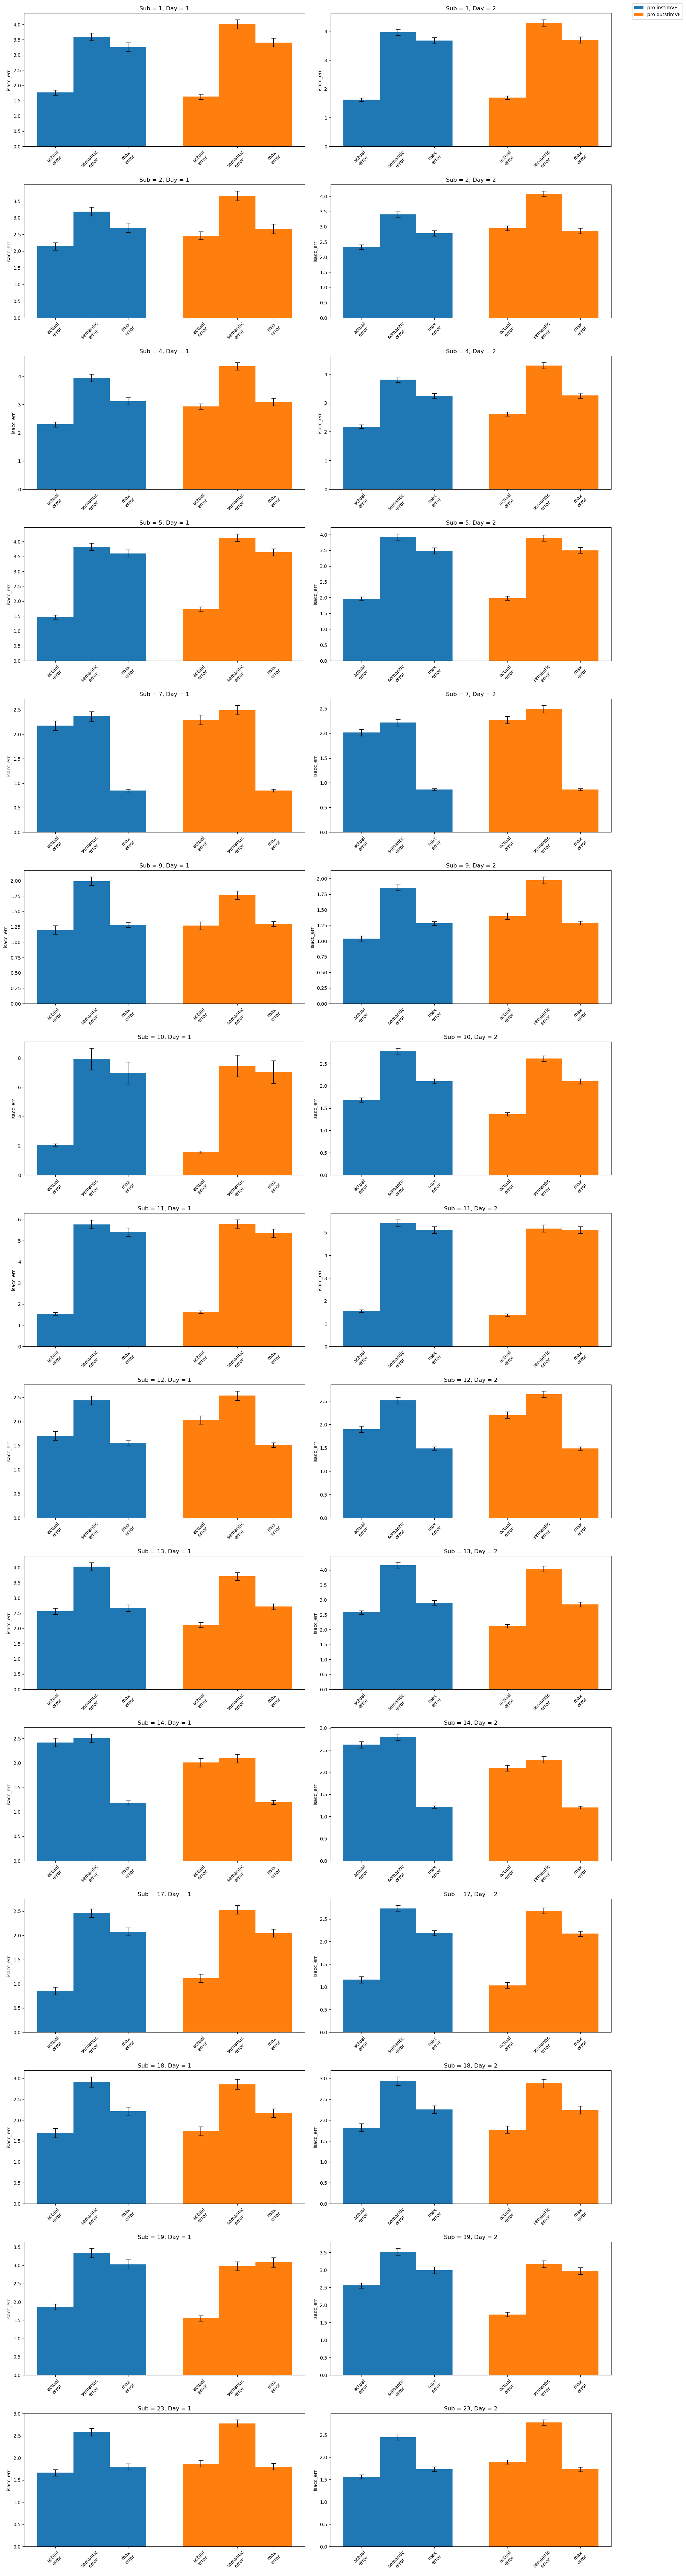

In [23]:
sub_list = np.unique(df_clean['subjID'].values)
#sub_list = [1, 3]
fig, axs = plt.subplots(len(sub_list), 2, figsize = (20, 5*len(sub_list)))
x = [0.5, 0.7, 0.9, 1.3, 1.5, 1.7]#, 2.1, 2.3, 2.5, 2.9, 3.1, 3.3]
bar_width = 0.2
labels = ['actual\nerror', 'semantic\nerror', 'max\nerror', 'actual\nerror', 'semantic\nerror', 'max\nerror']#,
          #'actual\nerror', 'semantic\nerror', 'max\nerror', 'actual\nerror', 'semantic\nerror', 'max\nerror']

legend_handles = []
for sub in range(len(sub_list)):
    this_sub = sub_list[sub]
    for day in range(2):
        df_pro_instimVF = df_clean[(df_clean['subjID'] == this_sub) & (df_clean['day'] == day+1) & (df_clean['instimVF'] == 1)]
        df_pro_outstimVF = df_clean[(df_clean['subjID'] == this_sub) & (df_clean['day'] == day+1) & (df_clean['instimVF'] == 0)]
        
        tr_num_pro_instimVF = ((df_pro_instimVF['rnum'] - 1) * 40 + df_pro_instimVF['tnum'])
        tr_num_pro_outstimVF = ((df_pro_outstimVF['rnum'] - 1) * 40 + df_pro_outstimVF['tnum'])
        
        Xpi_sem = np.median(df_pro_instimVF['TarX'])
        Ypi_sem = np.median(df_pro_instimVF['TarY'])
        Xpo_sem = np.median(df_pro_outstimVF['TarX'])
        Ypo_sem = np.median(df_pro_outstimVF['TarY'])

        errpi_sem = np.sqrt((df_pro_instimVF['isaccX']-Xpi_sem)**2+(df_pro_instimVF['isaccY']-Ypi_sem)**2)
        errpo_sem = np.sqrt((df_pro_outstimVF['isaccX']-Xpo_sem)**2+(df_pro_outstimVF['isaccY']-Ypo_sem)**2)
        
        tarpi_sem = np.sqrt((df_pro_instimVF['TarX']-Xpi_sem)**2+(df_pro_instimVF['TarY']-Ypi_sem)**2)
        tarpo_sem = np.sqrt((df_pro_outstimVF['TarX']-Xpo_sem)**2+(df_pro_outstimVF['TarY']-Ypo_sem)**2)        

        errpi = df_pro_instimVF['ierr']
        errpo = df_pro_outstimVF['ierr']
        
        pi_mean = [np.mean(errpi), np.mean(errpi_sem), np.mean(tarpi_sem)]
        po_mean = [np.mean(errpo), np.mean(errpo_sem), np.mean(tarpo_sem)]

        pi_var = [sem(errpi), sem(errpi_sem), sem(tarpi_sem)]
        po_var = [sem(errpo), sem(errpo_sem), sem(tarpo_sem)]

        
        bar1 = axs[sub, day].bar(x[:3], pi_mean, bar_width, label='pro instimVF', yerr=pi_var, capsize=5)
        bar2 = axs[sub, day].bar(x[3:6], po_mean, bar_width, label='pro outstimVF', yerr=po_var, capsize=5)

        legend_handles.extend([bar1, bar2])
        axs[sub, day].set_ylabel('isacc_err')
        axs[sub, day].set_title('Sub = ' + str(this_sub) + ', Day = ' + str(day+1))
        axs[sub, day].set_xticks(x)
        axs[sub, day].set_xticklabels(labels, rotation = 45)
        #axs[sub, day].legend()
fig.legend(legend_handles, ['pro instimVF', 'pro outstimVF'],
           loc='upper right', bbox_to_anchor=(1.0, 1.0))
# for ax in axs[-1]:
#     ax.set_xticklabels(labels, rotation=45, ha='right')  # Adjust rotation angle as needed

plt.subplots_adjust(right=0.85)  

#fig.suptitle('Learning curve')
plt.tight_layout(rect=[0, 0, 0.9, 1.0])  # Adjust the rect parameter as needed
# plt.savefig(save_folder + 'semantic_strategy.pdf', format="pdf", bbox_inches="tight")
plt.show()

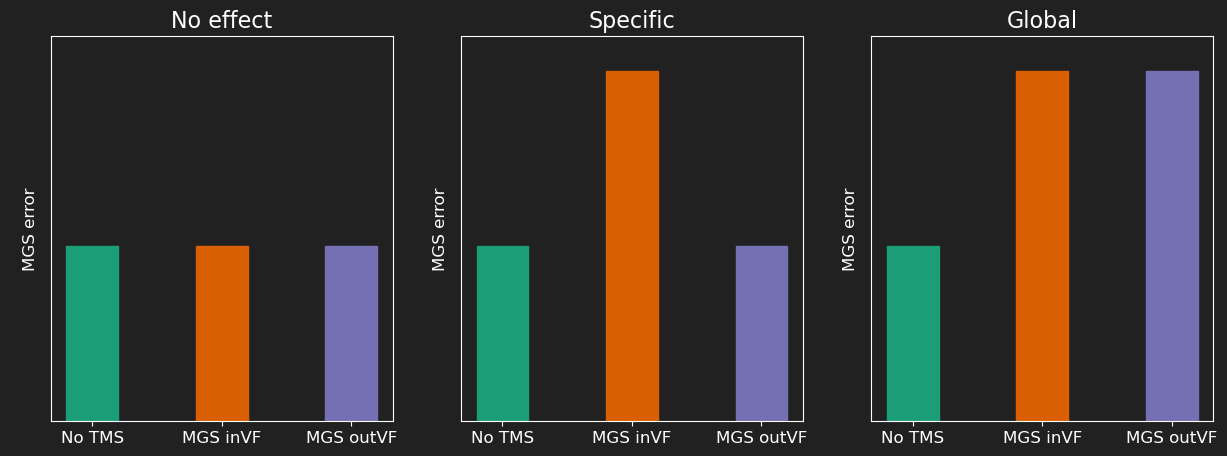

In [24]:
X1 = [0.3, 0.8, 1.3]
bWidth = 0.2
X2 = [round(x + 0.1, 1) for x in X1]
X_sum = [sum(value) for value in zip(X1, X2)]
x_tick_pos = [round(x/2, 2) for x in X1]
x_label_names = ['No TMS', 'MGS inVF', 'MGS outVF']
Y1_equal = [1, 1, 1]
Y1_specific = [1, 2, 1]
Y1_global = [1, 2, 2]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor((33/255, 33/255, 33/255))
axes_fontsize = 12
title_fontsize = 16
for ii in range(3):
    ax[ii].set_facecolor((33/255, 33/255, 33/255))
    ax[ii].spines['bottom'].set_color('white')
    ax[ii].spines['top'].set_color('white')
    ax[ii].spines['left'].set_color('white')
    ax[ii].spines['right'].set_color('white')
    ax[ii].xaxis.label.set_color('white')
    ax[ii].yaxis.label.set_color('white')
    ax[ii].tick_params(axis='x', colors='white')
    ax[ii].tick_params(axis='y', colors=(33/255, 33/255, 33/255))
    ax[ii].set_ylim((0, 2.2))
    ax[ii].set_xticks(X1, x_label_names, fontsize=axes_fontsize)
    ax[ii].set_ylabel('MGS error', fontsize=axes_fontsize, labelpad=-20)
    if ii == 0:
        bars = ax[ii].bar(X1, Y1_equal, width = bWidth)
        ax[ii].set_title('No effect', color = 'white', fontsize=title_fontsize)
    elif ii == 1:
        bars = ax[ii].bar(X1, Y1_specific, width = bWidth)
        ax[ii].set_title('Specific', color = 'white', fontsize=title_fontsize)
    elif ii == 2:
        bars = ax[ii].bar(X1, Y1_global, width = bWidth)
        ax[ii].set_title('Global', color = 'white', fontsize=title_fontsize)
    
    bars[0].set_color("#1B9E77")
    bars[1].set_color("#D95F02")
    bars[2].set_color("#7570B3")
plt.show()

In [ ]:
d_good = df[df['subjID'] != 18]
pro_rt = d_good[(d_good['ispro']==1) & (d_good['istms']== 0) & (d_good['instimVF'] == 1)]['isacc_rt']
anti_rt = d_good[(d_good['ispro']==0) & (d_good['istms']== 1) & (d_good['instimVF'] == 1)]['isacc_rt']

max_rt = max(np.max(pro_rt), np.max(anti_rt))
#print(max_rt)
nbins = 50
t_bins = np.linspace(0, max_rt, nbins)
t_res = 1/nbins
p_count = np.zeros((nbins, 1))
a_count = np.zeros((nbins, 1))
for ii in range(nbins):
    p_count[ii] = len(np.where((t_bins[ii]<pro_rt) & (pro_rt<t_bins[ii]+t_res))[0])
    a_count[ii] = len(np.where((t_bins[ii]<anti_rt) & (anti_rt<t_bins[ii]+t_res))[0])
p_count = np.cumsum(p_count)/len(pro_rt) * 100
a_count = np.cumsum(a_count)/len(anti_rt) * 100
print('Pro-saccade equivalence point: ' + str(int(round(t_bins[np.where(p_count < 75)[0][-1]]*1000, 0))) + 's')
print('Anti-saccade equivalence point: ' + str(int(round(t_bins[np.where(a_count < 75)[0][-1]]*1000, 0))) + 's')

plt.figure()
plt.plot(t_bins*1000, p_count, 'b-')
plt.plot(t_bins*1000, a_count, 'r-')
plt.xlabel('RT (ms)')
plt.ylabel('% Cummulative')
plt.title('No TMS')
plt.show()

In [ ]:
## Check for any existing trend in data due to eccentricity or angular width
subjIDs = df['subjID'].unique()
angular_width = np.zeros((len(subjIDs), 2) )
eccs = np.zeros((len(subjIDs),2) )
mean_err = np.zeros((len(subjIDs), 2))
median_err = np.zeros((len(subjIDs), 2))
var_err = np.zeros((len(subjIDs), 2))
range_err = np.zeros((len(subjIDs), 2))
err_met = 'isacc_err'

for ii in range(len(subjIDs)):
    this_subj_df_pro = df[(df['subjID']==subjIDs[ii]) & (df['TMS_condition']=='No TMS') & (df['ispro']==1) ]
    this_subj_df_anti = df[(df['subjID']==subjIDs[ii]) & (df['TMS_condition']=='No TMS') & (df['ispro']==0)]
    mean_err[ii, 0] = np.nanmean(this_subj_df_pro[err_met])
    median_err[ii, 0] = np.nanmedian(this_subj_df_pro[err_met])
    var_err[ii, 0] = np.nanvar(this_subj_df_pro[err_met])
    range_err[ii, 0] = np.nanmax(this_subj_df_pro[err_met]) - np.nanmin(this_subj_df_pro[err_met])
    mean_err[ii, 1] = np.nanmean(this_subj_df_anti[err_met])
    median_err[ii, 1] = np.nanmedian(this_subj_df_anti[err_met])
    var_err[ii, 1] = np.nanvar(this_subj_df_anti[err_met])
    range_err[ii, 1] = np.nanmax(this_subj_df_anti[err_met]) - np.nanmin(this_subj_df_anti[err_met])
    angular_width[ii, 0] = (this_subj_df_pro['TarTheta_rotated'].max() - this_subj_df_pro['TarTheta_rotated'].min()) * (180/np.pi)
    angular_width[ii, 1] = (this_subj_df_anti['TarTheta_rotated'].max() - this_subj_df_anti['TarTheta_rotated'].min()) * (180/np.pi)
    eccs[ii, 0] = this_subj_df_pro['TarRadius'].mean()
    eccs[ii, 1] = this_subj_df_anti['TarRadius'].mean()

fig, axs = plt.subplots(nrows = 2, ncols = 4, figsize = (20, 10))
axs[0, 0].plot(eccs[:, 0], mean_err[:, 0], 'bo')
axs[0, 0].plot(eccs[:, 1], mean_err[:, 1], 'ro')
axs[0, 0].set_xlabel('eccentricity')
axs[0, 0].set_ylabel('mean err')

axs[0, 1].plot(eccs[:, 0], median_err[:, 0], 'bo')
axs[0, 1].plot(eccs[:, 1], median_err[:, 1], 'ro')
axs[0, 1].set_xlabel('eccentricity')
axs[0, 1].set_ylabel('median err')

axs[0, 2].plot(eccs[:, 0], var_err[:, 0], 'bo')
axs[0, 2].plot(eccs[:, 1], var_err[:, 1], 'ro')
axs[0, 2].set_xlabel('eccentricity')
axs[0, 2].set_ylabel('var err')

axs[0, 3].plot(eccs[:, 0], range_err[:, 0], 'bo')
axs[0, 3].plot(eccs[:, 1], range_err[:, 1], 'ro')
axs[0, 3].set_xlabel('eccentricity')
axs[0, 3].set_ylabel('range err')

axs[1, 0].plot(angular_width[:, 0], mean_err[:, 0], 'bo')
axs[1, 0].plot(angular_width[:, 1], mean_err[:, 1], 'ro')
axs[1, 0].set_xlabel('angular_width')
axs[1, 0].set_ylabel('mean err')

axs[1, 1].plot(angular_width[:, 0], median_err[:, 0], 'bo')
axs[1, 1].plot(angular_width[:, 1], median_err[:, 1], 'ro')
axs[1, 1].set_xlabel('angular_width')
axs[1, 1].set_ylabel('median err')

axs[1, 2].plot(angular_width[:, 0], var_err[:, 0], 'bo')
axs[1, 2].plot(angular_width[:, 1], var_err[:, 1], 'ro')
axs[1, 2].set_xlabel('angular_width')
axs[1, 2].set_ylabel('var err')

axs[1, 3].plot(angular_width[:, 0], range_err[:, 0], 'bo')
axs[1, 3].plot(angular_width[:, 1], range_err[:, 1], 'ro')
axs[1, 3].set_xlabel('angular_width')
axs[1, 3].set_ylabel('range err')
plt.show()
